In [1]:
import time
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigsh


l_x, l_y = 1, 0.75

n_x = 60
n_y = 40

wanted = 3
eps = 1e-8
eps_rotations = 1e-12
seed = 0

**Тема 3.** Нахождение собственных значений и собственных векторов симметричных разреженных матриц большой размерности. Метод Ланцоша.

Для симметричной матрицы $A$ размера $n \times n$ нужно найти собственные значения $\lambda$ и собственные векторы $x \ne 0$:

$
Ax = \lambda x.
$

Матрица разреженная: ненулевых элементов в ней намного меньше, чем $n^2$. Размерность большая, и из этого следуют три ограничения:

- матрицу нельзя хранить целиком: при $n = 10^6$ это $8 \cdot 10^{12}$ байт;
- матрицу нельзя преобразовывать: преобразования подобия, которыми обычно приводят матрицу к простому виду, заполняют нулевые элементы (покажем это ниже);
- все $n$ собственных значений находить незачем, нужны несколько наибольших и наименьших.

Метод Ланцоша использует матрицу только в произведениях $Aq$ и находит крайние собственные значения. В работе:

1. выводим формулы метода;
2. реализуем хранение разреженной матрицы и умножение на вектор;
3. строим тестовые матрицы с известными собственными значениями;
4. реализуем метод и проверяем его;
5. исследуем, от чего зависят погрешность и число шагов.

# 1. Метод Ланцоша

## Трёхдиагональная матрица с теми же собственными значениями

Матрицы $A$ и $T = Q^{-1}AQ$ подобны, их собственные значения совпадают. Возьмём матрицу $Q$ ортогональной ($Q^TQ = E$, $Q^{-1} = Q^T$):

$
T = Q^TAQ.
$

Для симметричной $A$ матрица $T$ тоже симметрична: $T^T = Q^TA^TQ = T$. Подберём $Q$ так, чтобы $T$ имела форму Хессенберга, то есть нули ниже первой поддиагонали. Из симметрии нули тогда стоят и выше первой наддиагонали, и матрица $T$ трёхдиагональная:

$
T = \begin{pmatrix}
\alpha_1 & \beta_1 & & & \\
\beta_1 & \alpha_2 & \beta_2 & & \\
& \beta_2 & \alpha_3 & \ddots & \\
& & \ddots & \ddots & \beta_{n-1} \\
& & & \beta_{n-1} & \alpha_n
\end{pmatrix}.
$

Если $Ts = \theta s$, то $A(Qs) = QTs = \theta\,(Qs)$: собственные значения $A$ и $T$ общие, а собственные векторы $A$ равны $Qs$.

Обычно к такой форме приводят преобразованиями всей матрицы - отражениями или вращениями. Для большой разреженной матрицы это не годится: преобразования заполняют нулевые элементы. В методе Ланцоша столбцы $Q$ находят по одному, а матрица $A$ не меняется и участвует только в произведениях $Aq$.

## Процесс Ланцоша

Умножим $T = Q^TAQ$ слева на $Q$: $AQ = QT$. Обозначим столбцы $Q$ через $q_1, \ldots, q_n$ и приравняем $j$-е столбцы левой и правой частей:

$
Aq_j = \beta_{j-1}q_{j-1} + \alpha_jq_j + \beta_jq_{j+1}, \qquad \beta_0q_0 = 0.
$

Столбцы ортогональной матрицы ортонормированы: $(q_i, q_j) = 0$ при $i \ne j$ и $(q_j, q_j) = 1$. Умножим равенство скалярно на $q_j$:

$
\alpha_j = (Aq_j, q_j).
$

Перенесём известные слагаемые влево:

$
r_j = Aq_j - \alpha_jq_j - \beta_{j-1}q_{j-1} = \beta_jq_{j+1}.
$

Длина $q_{j+1}$ равна единице, поэтому

$
\beta_j = \|r_j\|_2, \qquad q_{j+1} = \dfrac{r_j}{\beta_j}.
$

Получился процесс: берём произвольный вектор $q_1$ единичной длины и для $j = 1, 2, \ldots$ вычисляем $\alpha_j$, $r_j$, $\beta_j$, $q_{j+1}$. Один шаг - это одно умножение матрицы на вектор и несколько операций с векторами. Если на каком-то шаге $\beta_j = 0$, процесс заканчивается.

## Ортогональность построенных векторов

Формулы получены в предположении, что векторы $q_j$ ортонормированы. Проверим, что процесс действительно строит такие векторы. Пусть $q_1, \ldots, q_j$ ортонормированы. Покажем, что $r_j$ ортогонален каждому из них. Для симметричной матрицы $(Ax, y) = (x, Ay)$, поэтому:

- $(r_j, q_j) = (Aq_j, q_j) - \alpha_j = 0$ по выбору $\alpha_j$;
- $(r_j, q_{j-1}) = (q_j, Aq_{j-1}) - \beta_{j-1} = (q_j,\ \beta_{j-2}q_{j-2} + \alpha_{j-1}q_{j-1} + \beta_{j-1}q_j) - \beta_{j-1} = 0$;
- при $i < j - 1$: $(r_j, q_i) = (q_j, Aq_i) = (q_j,\ \beta_{i-1}q_{i-1} + \alpha_iq_i + \beta_iq_{i+1}) = 0$, так как $i + 1 < j$.

Значит, вектор $q_{j+1} = r_j / \beta_j$ ортогонален всем предыдущим. В формуле для $r_j$ участвуют только два последних вектора, а ортогональность остальным получается сама. Это следствие симметрии $A$.

## Приближения после $m$ шагов

Для большой матрицы делаем $m \ll n$ шагов. Соберём первые $m$ равенств в одно матричное:

$
AQ_m = Q_mT_m + \beta_mq_{m+1}e_m^T,
$

где $Q_m$ - матрица $n \times m$ со столбцами $q_1, \ldots, q_m$, $T_m$ - левый верхний блок $m \times m$ матрицы $T$, $e_m$ - последний столбец единичной матрицы порядка $m$. Умножив равенство слева на $Q_m^T$, получим $T_m = Q_m^TAQ_m$.

Малая матрица $T_m$ симметрична. Найдём все её собственные пары:

$
T_ms_i = \theta_is_i, \qquad \|s_i\|_2 = 1, \qquad i = \overline{1, m}.
$

За приближения к собственным парам $A$ примем числа $\theta_i$ и векторы $y_i = Q_ms_i$. Длина $y_i$ равна единице, так как столбцы $Q_m$ ортонормированы. Подставим их в матричное равенство:

$
Ay_i - \theta_iy_i = AQ_ms_i - \theta_iQ_ms_i = Q_m(T_ms_i - \theta_is_i) + \beta_mq_{m+1}(e_m^Ts_i) = \beta_ms_{mi}\,q_{m+1},
$

где $s_{mi}$ - последняя компонента вектора $s_i$. Норма невязки

$
\|Ay_i - \theta_iy_i\|_2 = \beta_m|s_{mi}|.
$

Она вычисляется без самого вектора $y_i$ и без умножений на $A$. В частности, если процесс закончился с $\beta_m = 0$, все невязки нулевые: числа $\theta_i$ - точные собственные значения $A$.

**Насколько $\theta_i$ близко к собственному значению.** У симметричной матрицы $A$ есть $n$ ортонормированных собственных векторов $x_1, \ldots, x_n$. Разложим по ним вектор $y$ единичной длины: $y = \sum_k c_kx_k$, $\sum_k c_k^2 = 1$. Тогда

$
\|Ay - \theta y\|_2^2 = \Bigl\|\sum_k c_k(\lambda_k - \theta)x_k\Bigr\|_2^2 = \sum_k c_k^2(\lambda_k - \theta)^2 \ge \min_k(\lambda_k - \theta)^2.
$

Значит, на расстоянии не больше невязки от $\theta_i$ есть собственное значение матрицы $A$:

$
\min_k|\lambda_k - \theta_i| \le \beta_m|s_{mi}|.
$

Отсюда критерий остановки: процесс заканчиваем, когда для всех искомых пар $\beta_m|s_{mi}| \le \varepsilon\max\limits_i|\theta_i|$.

## Связь со степенным методом

Степенной метод строит векторы $y^{(k)} = Ay^{(k-1)} = A^ky^{(0)}$ и оценивает наибольшее по модулю собственное значение по последнему из них: $\lambda_1^{(k)} = (y^{(k)}, Ay^{(k)})$ для вектора единичной длины.

Из формул процесса по индукции следует, что $q_j$ - линейная комбинация векторов $q_1, Aq_1, \ldots, A^{j-1}q_1$. Если взять $q_1 = y^{(0)} / \|y^{(0)}\|_2$, то столбцы $Q_m$ - это ортонормированный базис во множестве всех линейных комбинаций векторов степенного метода $y^{(0)}, \ldots, y^{(m-1)}$.

Для любого вектора $y = Q_ms$ из этого множества

$
\dfrac{(Ay, y)}{(y, y)} = \dfrac{(T_ms, s)}{(s, s)} \le \theta_{\max},
$

где $\theta_{\max}$ - наибольшее собственное значение $T_m$. Неравенство получается разложением $s$ по ортонормированным собственным векторам $T_m$: $(T_ms, s) = \sum_i \theta_ic_i^2 \le \theta_{\max}\sum_i c_i^2$. Равенство достигается на собственном векторе, отвечающем $\theta_{\max}$.

Отсюда три следствия.

1. $\theta_{\max}$ - наибольшее значение отношения $(Ay, y)/(y, y)$ по всем комбинациям векторов степенного метода, а степенной метод берёт это отношение только для последнего вектора. Поэтому при одинаковом числе умножений на матрицу оценка метода Ланцоша не хуже оценки степенного метода.
2. То же неравенство для самой матрицы $A$ даёт $(Ay, y)/(y, y) \le \lambda_{\max}$, поэтому $\theta_{\max} \le \lambda_{\max}$: приближение подходит к наибольшему собственному значению снизу. Аналогично $\theta_{\min} \ge \lambda_{\min}$.
3. С ростом $m$ множество комбинаций расширяется, поэтому $\theta_{\max}$ не убывает, а $\theta_{\min}$ не возрастает.

Степенной метод сходится к наибольшему по модулю собственному значению. Если все собственные значения положительны, как у тестовых матриц этой работы, то это $\lambda_{\max}$, и в первом следствии обе оценки относятся к одной и той же величине.

## Ошибки округления и переортогонализация

В точной арифметике $(r_j, q_i) = 0$ для всех $i \le j$. При вычислениях с округлением эти произведения не равны нулю, и ошибка накапливается от шага к шагу. Насколько - посмотрим в исследовании. Чтобы её убрать, после вычисления $r_j$ явно вычтем его проекции на все уже построенные векторы:

$
r_j \leftarrow r_j - \sum_{i=1}^{j}(r_j, q_i)\,q_i.
$

В точной арифметике все слагаемые суммы нулевые, так что метод не меняется. Цена - хранить все векторы $q_i$ и тратить на шаге порядка $nm$ операций вместо порядка $n$. Это полная переортогонализация.

------

# 2. Разреженная матрица

Храним только ненулевые элементы, строка за строкой, в трёх массивах:

- `values` - сами элементы;
- `columns` - номер столбца каждого элемента;
- `row_start` - с какой позиции в `values` начинается каждая строка (длина $n + 1$).

Память пропорциональна числу ненулевых элементов, а не $n^2$.

Умножение на вектор - по определению, но только по ненулевым элементам:

$
(Ax)_i = \sum_{k\,:\ \text{элемент } k \text{ стоит в строке } i} \text{values}_k \cdot x_{\text{columns}_k}.
$

Чтобы записать его одной векторной операцией, храним ещё массив `rows` с номером строки каждого элемента. Тогда $(Ax)_i$ - сумма произведений `values * x[columns]` по элементам, у которых `rows` равно $i$. Такую сумму считает `np.bincount`.

Матрицу собираем из троек (строка, столбец, значение). Тройки с одинаковыми индексами складываются.

In [2]:
@dataclass(frozen=True)
class SparseMatrix:
    n: int
    values: np.ndarray
    columns: np.ndarray
    row_start: np.ndarray
    rows: np.ndarray


def sparse_matrix(n, rows, columns, values):
    keys, inverse = np.unique(rows * n + columns, return_inverse=True)
    values = np.bincount(inverse, weights=values, minlength=len(keys))
    rows, columns = keys // n, keys % n
    row_start = np.concatenate(([0], np.cumsum(np.bincount(rows, minlength=n))))
    return SparseMatrix(n, values, columns, row_start, rows)


def multiply(A, x):
    return np.bincount(A.rows, weights=A.values * x[A.columns], minlength=A.n)


def to_dense(A):
    dense = np.zeros((A.n, A.n))
    dense[A.rows, A.columns] = A.values
    return dense


def memory(A):
    return A.values.nbytes + A.columns.nbytes + A.row_start.nbytes + A.rows.nbytes

Проверим сборку и умножение на случайной матрице. Плотную матрицу строим независимо, прямо из троек, и сравниваем с ней собранную матрицу и результат умножения.

In [3]:
rng = np.random.default_rng(seed)
size, count = 200, 1000
triple_rows, triple_columns = rng.integers(0, size, count), rng.integers(0, size, count)
triple_values, x_check = rng.standard_normal(count), rng.standard_normal(size)

A_check = sparse_matrix(size, triple_rows, triple_columns, triple_values)

dense_check = np.zeros((size, size))
np.add.at(dense_check, (triple_rows, triple_columns), triple_values)

print(f'троек: {count}, ненулевых элементов после сложения совпадающих: {len(A_check.values)} из {size**2}')
print('расхождение собранной матрицы с плотной:', np.abs(to_dense(A_check) - dense_check).max())
print('расхождение с умножением плотной матрицы:', np.abs(multiply(A_check, x_check) - dense_check @ x_check).max())

троек: 1000, ненулевых элементов после сложения совпадающих: 987 из 40000
расхождение собранной матрицы с плотной: 0.0
расхождение с умножением плотной матрицы: 1.3322676295501878e-15


------

# 3. Тестовые матрицы

## Сеточная матрица

Возьмём матрицу пятиточечной разностной схемы для оператора $-\left(\dfrac{\partial^2}{\partial x^2} + \dfrac{\partial^2}{\partial y^2}\right)$ в прямоугольнике $[0, l_x] \times [0, l_y]$ с нулевыми значениями на границе. Сетка: $x_i = ih_x$, $y_j = jh_y$, $h_x = l_x / n_x$, $h_y = l_y / n_y$. Неизвестные - значения во внутренних узлах $i = \overline{1, n_x - 1}$, $j = \overline{1, n_y - 1}$, всего $n = (n_x - 1)(n_y - 1)$:

$
(Au)_{ij} = \dfrac{2u_{ij} - u_{i-1,j} - u_{i+1,j}}{h_x^2} + \dfrac{2u_{ij} - u_{i,j-1} - u_{i,j+1}}{h_y^2}, \qquad u_{0j} = u_{n_xj} = u_{i0} = u_{in_y} = 0.
$

В каждой строке не больше пяти ненулевых элементов, матрица симметрична. Неизвестные нумеруем подряд - сначала все узлы с $i = 1$, затем с $i = 2$ и так далее: узлу $(i, j)$ отвечает номер $(i - 1)(n_y - 1) + (j - 1)$.

**Собственные пары этой матрицы известны.** Для $p = \overline{1, n_x - 1}$, $q = \overline{1, n_y - 1}$

$
v^{(pq)}_{ij} = \sin\dfrac{p\pi i}{n_x}\,\sin\dfrac{q\pi j}{n_y}, \qquad
\lambda_{pq} = \dfrac{4}{h_x^2}\sin^2\dfrac{p\pi}{2n_x} + \dfrac{4}{h_y^2}\sin^2\dfrac{q\pi}{2n_y}.
$

Проверяется подстановкой. По формуле $\sin(a - b) + \sin(a + b) = 2\sin a\cos b$

$
2\sin\dfrac{p\pi i}{n_x} - \sin\dfrac{p\pi(i - 1)}{n_x} - \sin\dfrac{p\pi(i + 1)}{n_x} = \left(2 - 2\cos\dfrac{p\pi}{n_x}\right)\sin\dfrac{p\pi i}{n_x} = 4\sin^2\dfrac{p\pi}{2n_x}\,\sin\dfrac{p\pi i}{n_x},
$

и так же по $j$. Граничные значения нулевые сами: $\sin 0 = \sin p\pi = 0$. Пар получается $(n_x - 1)(n_y - 1) = n$. Что других собственных значений у матрицы нет, проверим численно: сравним формулу со всеми $n$ собственными значениями, которые находит библиотечная функция для плотной матрицы.

При малых шагах $\dfrac{4}{h_x^2}\sin^2\dfrac{p\pi}{2n_x} \approx \left(\dfrac{p\pi}{l_x}\right)^2$, поэтому наименьшие собственные значения близки к $\pi^2\left(\dfrac{p^2}{l_x^2} + \dfrac{q^2}{l_y^2}\right)$.

Прямоугольник берём неквадратным, $l_x = 1$, $l_y = 0.75$, чтобы среди крайних собственных значений не было кратных. Кратные значения рассмотрим отдельно.

In [4]:
@dataclass(frozen=True)
class Grid:
    n_x: int
    n_y: int
    l_x: float = l_x
    l_y: float = l_y


def grid_matrix(grid):
    h_x, h_y = grid.l_x / grid.n_x, grid.l_y / grid.n_y
    number = np.arange((grid.n_x - 1) * (grid.n_y - 1)).reshape(grid.n_x - 1, grid.n_y - 1)

    rows = [number.ravel()]
    columns = [number.ravel()]
    values = [np.full(number.size, 2 / h_x**2 + 2 / h_y**2)]

    for first, second, value in [
        (number[1:, :], number[:-1, :], -1 / h_x**2),
        (number[:, 1:], number[:, :-1], -1 / h_y**2),
    ]:
        rows += [first.ravel(), second.ravel()]
        columns += [second.ravel(), first.ravel()]
        values += [np.full(first.size, value)] * 2

    return sparse_matrix(number.size, np.concatenate(rows), np.concatenate(columns), np.concatenate(values))


def grid_spectrum(grid):
    h_x, h_y = grid.l_x / grid.n_x, grid.l_y / grid.n_y
    p, q = np.arange(1, grid.n_x), np.arange(1, grid.n_y)
    values = (4 / h_x**2 * np.sin(p * np.pi / (2 * grid.n_x))**2)[:, None] + (4 / h_y**2 * np.sin(q * np.pi / (2 * grid.n_y))**2)[None, :]

    order = np.argsort(values, axis=None)
    index_p, index_q = np.unravel_index(order, values.shape)
    return values.ravel()[order], p[index_p], q[index_q]


def grid_eigenvector(grid, p, q):
    i, j = np.arange(1, grid.n_x), np.arange(1, grid.n_y)
    v = np.outer(np.sin(p * np.pi * i / grid.n_x), np.sin(q * np.pi * j / grid.n_y)).ravel()
    return v / np.linalg.norm(v)

Основная матрица - сетка $60 \times 40$. Функция `grid_spectrum` возвращает собственные значения по возрастанию и номера $(p, q)$ каждого из них. Подставим несколько собственных пар в $Av = \lambda v$ и сравним все $n$ собственных значений с `np.linalg.eigvalsh`:

In [5]:
grid = Grid(n_x, n_y)
A = grid_matrix(grid)
exact, mode_p, mode_q = grid_spectrum(grid)

print(f'n = {A.n}, ненулевых элементов: {len(A.values)} ({len(A.values) / A.n**2:.2%} от n^2)')
print('симметрия, max |A - A^T|:', np.abs(to_dense(A) - to_dense(A).T).max())

substitution = 0
for index in [0, 1, 2, A.n // 2, A.n - 3, A.n - 2, A.n - 1]:
    v = grid_eigenvector(grid, mode_p[index], mode_q[index])
    substitution = max(substitution, np.abs(multiply(A, v) - exact[index] * v).max())
print('подстановка собственных пар, max |Av - λv|:', substitution)

dense_values = np.linalg.eigvalsh(to_dense(A))
print(f'все {A.n} собственных значений, расхождение формулы с np.linalg.eigvalsh:', np.abs(dense_values - exact).max())

n = 2301, ненулевых элементов: 11309 (0.21% от n^2)
симметрия, max |A - A^T|: 0.0
подстановка собственных пар, max |Av - λv|: 8.355982572538778e-12


все 2301 собственных значений, расхождение формулы с np.linalg.eigvalsh: 9.094947017729282e-11


In [6]:
ends = [*range(wanted), *range(-wanted, 0)]
limit = np.pi**2 * (mode_p[ends]**2 / l_x**2 + mode_q[ends]**2 / l_y**2)
limit[wanted:] = np.nan

pd.DataFrame({
    'p': mode_p[ends],
    'q': mode_q[ends],
    'λ': exact[ends],
    'π²(p²/l_x² + q²/l_y²)': limit,
}, index=pd.Index([*range(1, wanted + 1), *range(A.n - wanted + 1, A.n + 1)], name='номер по возрастанию')).style.format(
    {'λ': '{:.6f}', 'π²(p²/l_x² + q²/l_y²)': '{:.6f}'}, na_rep='-')

,p,q,λ,π²(p²/l_x² + q²/l_y²)
номер по возрастанию,,,,
1,1,1,27.404296,27.415568
2,2,1,56.979299,57.024381
3,1,2,79.907012,80.053458
2299,59,38,25697.870766,-
2300,58,39,25720.798479,-
2301,59,39,25750.373482,-


Формула даёт все собственные значения матрицы: по всем 2301 значениям расхождение с `np.linalg.eigvalsh` равно $9 \cdot 10^{-11}$, то есть $4 \cdot 10^{-15}$ относительно $\lambda_{\max}$.

Матрица заполнена на 0.21 %. Наименьшие собственные значения близки к $\pi^2\left(p^2/l_x^2 + q^2/l_y^2\right)$: например, $27.404$ против $27.416$.

Крайние собственные значения расположены тесно по сравнению с шириной спектра: наибольшее равно $25750.4$, а до соседнего от него всего $29.6$. От этого зависит число шагов метода - это будет видно в исследованиях.

## Преобразования всей матрицы заполняют нули

Привести симметричную матрицу к трёхдиагональному виду можно отражениями Хаусхолдера

$
H = E - \dfrac{2}{v^Tv}vv^T, \qquad v = b + \operatorname{sign}(b_1)\|b\|_2e_1.
$

На шаге $j$ вектор $b$ - это часть $j$-го столбца ниже диагонали. Отражение действует только на строки и столбцы с номерами больше $j$ (остальная часть $H$ - единичная матрица), и преобразование $A \leftarrow HAH$ обнуляет в этой части столбца всё, кроме первого элемента. Посмотрим на небольшой сеточной матрице, сколько ненулевых элементов оказывается в матрице по ходу такого приведения.

n = 266, ненулевых элементов до приведения: 1264 (1.8%)
наибольшее число по ходу приведения: 55786 (78.8%) на шаге 29
в трёхдиагональной матрице: 792
собственные значения сохранились, расхождение: 1.2278178473934531e-11


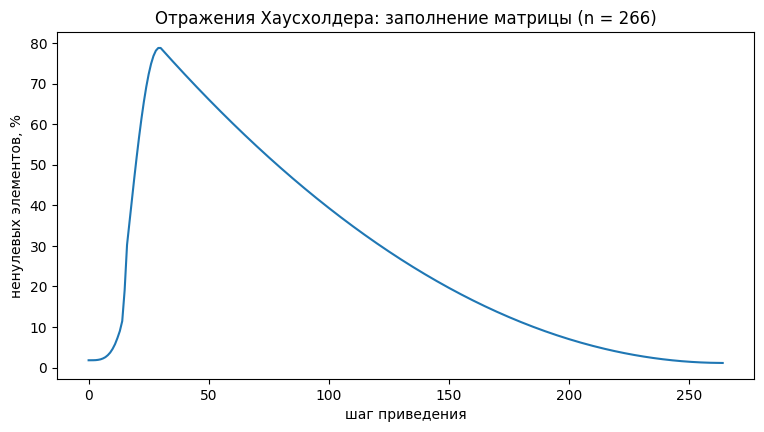

In [7]:
def householder_fill(A):
    D = to_dense(A)
    size = len(D)
    threshold = 1e-12 * np.abs(D).max()
    filled = [np.count_nonzero(np.abs(D) > threshold)]

    for j in range(size - 2):
        b = D[j + 1:, j]
        v = b.copy()
        v[0] += (1 if b[0] >= 0 else -1) * np.linalg.norm(b)

        if v @ v > 0:
            H = np.eye(size - j - 1) - 2 * np.outer(v, v) / (v @ v)
            D[j + 1:, :] = H @ D[j + 1:, :]
            D[:, j + 1:] = D[:, j + 1:] @ H

        filled.append(np.count_nonzero(np.abs(D) > threshold))

    return np.array(filled), D


small_grid = Grid(20, 15)
filled, reduced = householder_fill(grid_matrix(small_grid))
size = len(reduced)

print(f'n = {size}, ненулевых элементов до приведения: {filled[0]} ({filled[0] / size**2:.1%})')
print(f'наибольшее число по ходу приведения: {filled.max()} ({filled.max() / size**2:.1%}) на шаге {filled.argmax()}')
print(f'в трёхдиагональной матрице: {filled[-1]}')
print('собственные значения сохранились, расхождение:', np.abs(np.linalg.eigvalsh(reduced) - grid_spectrum(small_grid)[0]).max())

plt.figure(figsize=(9, 4.5))
ax = sns.lineplot(x=np.arange(len(filled)), y=100 * filled / size**2)
ax.set(title=f'Отражения Хаусхолдера: заполнение матрицы (n = {size})', xlabel='шаг приведения', ylabel='ненулевых элементов, %');

В исходной матрице 1.8 % ненулевых элементов. Уже на 29-м шаге приведения заполнено 78.8 % матрицы: хранить её приходится целиком. Для матрицы порядка $10^6$ это невозможно. Метод Ланцоша приходит к трёхдиагональной матрице, не меняя $A$.

## Диагональная матрица с заданным спектром

Процесс Ланцоша использует матрицу только в произведениях $Aq$ и в скалярных произведениях. Пусть $B = U^TAU$ с ортогональной $U$, а начальный вектор равен $U^Tq_1$. Тогда векторы процесса для $B$ равны $U^Tq_j$, а коэффициенты те же, что для $A$:

$
(BU^Tq_j, U^Tq_j) = (U^TAq_j, U^Tq_j) = (Aq_j, q_j),
$

потому что ортогональная матрица сохраняет скалярное произведение. Любая симметричная матрица ортогональным преобразованием приводится к диагональной. Значит, ход процесса зависит только от собственных значений матрицы и от разложения начального вектора по её собственным векторам, и изучать его можно на диагональной матрице с нужным спектром. Собственные значения такой матрицы - её диагональные элементы, собственные векторы - столбцы единичной матрицы.

In [8]:
def diagonal_matrix(d):
    index = np.arange(len(d))
    return sparse_matrix(len(d), index, index, np.asarray(d, dtype=float))

------

# 4. Метод вращений для малой матрицы

Собственные пары симметричной матрицы $T_m$ находим методом вращений Якоби. На каждой итерации:

1. выбирается максимальный по модулю наддиагональный элемент $a_{ij}$;
2. строится матрица вращения $U$: $u_{ii} = u_{jj} = \cos\varphi$, $u_{ij} = -\sin\varphi$, $u_{ji} = \sin\varphi$, остальные элементы как у единичной матрицы. Угол выбирается так, чтобы элемент $a_{ij}$ обнулился:

$
\varphi = \dfrac{1}{2}\operatorname{arctg}\dfrac{2a_{ij}}{a_{ii} - a_{jj}}, \qquad \varphi = \dfrac{\pi}{4} \text{ при } a_{ii} = a_{jj};
$

3. выполняется преобразование подобия $A \leftarrow U^TAU$.

Итерации заканчиваются, когда сумма квадратов наддиагональных элементов мала: $t(A) = \Bigl(\sum\limits_{l < k} a_{lk}^2\Bigr)^{1/2} \le \varepsilon$. Собственные значения - диагональные элементы полученной матрицы, собственные векторы - столбцы произведения всех матриц вращения.

Особенности реализации:

- вращение меняет только строки и столбцы с номерами $i$ и $j$, поэтому матрицы целиком не перемножаем, а пересчитываем две строки и два столбца;
- угол считаем через `arctan2`: условие обнуления задаёт только $\operatorname{tg}2\varphi$, а отдельный случай $a_{ii} = a_{jj}$ тогда не нужен;
- максимальный элемент ищем в два приёма: сначала максимумы по строкам, затем наибольший из них. Так быстрее, а элемент тот же;
- критерий $t(A)$ проверяем один раз на $m$ вращений, чтобы не считать сумму на каждой итерации;
- число вращений ограничено величиной $100m^2$. Это защита от зацикливания на случай, если заданная точность недостижима из-за округления; в расчётах хватает меньше $2m^2$ вращений.

In [9]:
def jacobi_rotations(A, eps):
    A = A.copy()
    size = len(A)
    U = np.eye(size)
    upper = np.abs(np.triu(A, 1))
    rotations, max_rotations = 0, 100 * size**2

    while np.sqrt((upper**2).sum()) > eps and rotations < max_rotations:
        for _ in range(size):
            i = upper.max(axis=1).argmax()
            j = upper[i].argmax()
            if upper[i, j] == 0:
                break

            phi = 0.5 * np.arctan2(2 * A[i, j], A[i, i] - A[j, j])
            c, s = np.cos(phi), np.sin(phi)

            A[:, i], A[:, j] = c * A[:, i] + s * A[:, j], -s * A[:, i] + c * A[:, j]
            A[i], A[j] = c * A[i] + s * A[j], -s * A[i] + c * A[j]
            U[:, i], U[:, j] = c * U[:, i] + s * U[:, j], -s * U[:, i] + c * U[:, j]

            for index in (i, j):
                upper[index, index + 1:] = np.abs(A[index, index + 1:])
                upper[:index, index] = np.abs(A[:index, index])
            rotations += 1

    return np.diag(A).copy(), U, rotations

Проверим на случайной симметричной матрице: сравним с `np.linalg.eigh`, проверим равенство $AU = U\Lambda$ и ортогональность $U$.

In [10]:
B_check = np.random.default_rng(seed).standard_normal((40, 40))
B_check = B_check + B_check.T

values_check, U_check, rotations_check = jacobi_rotations(B_check, eps_rotations * np.abs(B_check).max())

print(f'вращений: {rotations_check} ({rotations_check / 40**2:.2f} m^2)')
print('расхождение с np.linalg.eigh:', np.abs(np.sort(values_check) - np.linalg.eigh(B_check)[0]).max())
print('max |AU - UΛ|:', np.abs(B_check @ U_check - U_check * values_check).max())
print('max |U^T U - E|:', np.abs(U_check.T @ U_check - np.eye(40)).max())

вращений: 3080 (1.93 m^2)
расхождение с np.linalg.eigh: 3.552713678800501e-14
max |AU - UΛ|: 3.967381978497997e-13
max |U^T U - E|: 2.220446049250313e-15


------

# 5. Реализация метода Ланцоша

Функция `lanczos` выполняет шаги процесса и хранит векторы $q_j$ по строкам массива `Q`. Каждые `check_every` шагов решается малая задача для $T_m$ и проверяется условие остановки `converged`. Результаты этих проверок сохраняются в `checks`: по ним потом видно, как сходились приближения.

Функция `ritz_pairs` возвращает собственные значения $\theta_i$ матрицы $T_m$ по возрастанию, векторы $s_i$ и оценки невязки $\beta_m|s_{mi}|$. Вектор $y_i = Q_ms_i$ строит `ritz_vector`.

In [11]:
@dataclass(frozen=True)
class RitzPairs:
    values: np.ndarray
    vectors: np.ndarray
    residuals: np.ndarray


@dataclass(frozen=True)
class LanczosResult:
    alphas: np.ndarray
    betas: np.ndarray
    Q: np.ndarray
    checks: dict = field(default_factory=dict)


def tridiagonal(alphas, betas):
    m = len(alphas)
    return np.diag(alphas) + np.diag(betas[:m - 1], 1) + np.diag(betas[:m - 1], -1)


def ritz_pairs(result, m=None):
    m = len(result.alphas) if m is None else m
    T = tridiagonal(result.alphas[:m], result.betas[:m])
    values, S, _ = jacobi_rotations(T, eps_rotations * np.abs(T).max())

    order = np.argsort(values)
    return RitzPairs(values[order], S[:, order], result.betas[m - 1] * np.abs(S[-1, order]))


def ritz_vector(result, pairs, index):
    return result.Q[:len(pairs.values)].T @ pairs.vectors[:, index]


def lanczos(A, q_1, max_steps, reorthogonalize=True, converged=None, check_every=10):
    Q = np.zeros((max_steps + 1, A.n))
    alphas, betas = np.zeros(max_steps), np.zeros(max_steps)
    checks = {}
    Q[0] = q_1 / np.linalg.norm(q_1)

    for j in range(max_steps):
        r = multiply(A, Q[j])
        alphas[j] = r @ Q[j]
        r -= alphas[j] * Q[j]
        if j > 0:
            r -= betas[j - 1] * Q[j - 1]
        if reorthogonalize:
            r -= Q[:j + 1].T @ (Q[:j + 1] @ r)

        betas[j] = np.linalg.norm(r)
        steps = j + 1
        if betas[j] <= 1e-12 * np.abs(alphas[:steps]).max():
            break
        Q[j + 1] = r / betas[j]

        if converged is not None and steps % check_every == 0:
            checks[steps] = ritz_pairs(LanczosResult(alphas[:steps], betas[:steps], Q[:steps + 1]))
            if converged(checks[steps]):
                break

    return LanczosResult(alphas[:steps], betas[:steps], Q[:steps + 1], checks)

Условия остановки. Основное - по оценке невязки для `count` наименьших и `count` наибольших значений. Второе нужно только в исследованиях на матрицах с известным спектром: оно останавливает процесс, когда наибольшее приближение подошло к точному значению ближе заданного допуска.

In [12]:
def extremes_converged(count, eps):
    def converged(pairs):
        if len(pairs.values) < 2 * count:
            return False
        index = np.r_[0:count, -count:0]
        return bool(np.all(pairs.residuals[index] <= eps * np.abs(pairs.values).max()))

    return converged


def largest_within(exact_value, tolerance):
    return lambda pairs: abs(pairs.values[-1] - exact_value) <= tolerance

## Проверка на малой матрице

Сеточная матрица $8 \times 6$, $n = 35$. Сначала $m = 20$ шагов: проверим матричное равенство $AQ_m = Q_mT_m + \beta_mq_{m+1}e_m^T$, ортогональность векторов и формулу невязки. Затем $m = n$ шагов: тогда $T_n$ подобна $A$, и её собственные значения должны совпасть со всеми собственными значениями $A$. В конце возьмём начальный вектор, равный сумме трёх собственных векторов: процесс должен оборваться на третьем шаге с $\beta_3 = 0$ и дать три точных собственных значения.

In [13]:
tiny_grid = Grid(8, 6)
A_tiny = grid_matrix(tiny_grid)
exact_tiny, p_tiny, q_tiny_modes = grid_spectrum(tiny_grid)
q_tiny = np.random.default_rng(seed).standard_normal(A_tiny.n)

m = 20
result_tiny = lanczos(A_tiny, q_tiny, m)
pairs_tiny = ritz_pairs(result_tiny)
Q_m = result_tiny.Q[:m].T

identity = to_dense(A_tiny) @ Q_m - Q_m @ tridiagonal(result_tiny.alphas, result_tiny.betas)
identity[:, -1] -= result_tiny.betas[-1] * result_tiny.Q[m]
true_residuals = np.array([
    np.linalg.norm(multiply(A_tiny, ritz_vector(result_tiny, pairs_tiny, index)) - pairs_tiny.values[index] * ritz_vector(result_tiny, pairs_tiny, index))
    for index in range(m)
])

print('max |A Q_m - Q_m T_m - β_m q_{m+1} e_m^T|:', np.abs(identity).max())
print('max |Q_m^T Q_m - E|:', np.abs(Q_m.T @ Q_m - np.eye(m)).max())
print('max |невязка - β_m |s_mi||:', np.abs(true_residuals - pairs_tiny.residuals).max())

result_full = lanczos(A_tiny, q_tiny, A_tiny.n)
print(f'm = n = {len(result_full.alphas)}: расхождение собственных значений T_n и A:', np.abs(ritz_pairs(result_full).values - exact_tiny).max())

three = [0, 10, 34]
result_three = lanczos(A_tiny, sum(grid_eigenvector(tiny_grid, p_tiny[index], q_tiny_modes[index]) for index in three), A_tiny.n)
print(f'сумма трёх собственных векторов: шагов {len(result_three.alphas)}, расхождение с их собственными значениями:',
      np.abs(ritz_pairs(result_three).values - exact_tiny[three]).max())

max |A Q_m - Q_m T_m - β_m q_{m+1} e_m^T|: 4.973799150320701e-14
max |Q_m^T Q_m - E|: 4.440892098500626e-16
max |невязка - β_m |s_mi||: 1.4210854715202004e-14
m = n = 35: расхождение собственных значений T_n и A: 5.115907697472721e-13
сумма трёх собственных векторов: шагов 3, расхождение с их собственными значениями: 4.547473508864641e-13


Матричное равенство и формула невязки выполняются с точностью до ошибок округления ($5 \cdot 10^{-14}$ и $1 \cdot 10^{-14}$), векторы ортонормированы с точностью $4 \cdot 10^{-16}$. За $n$ шагов получена трёхдиагональная матрица с теми же собственными значениями, что у $A$: расхождение $5 \cdot 10^{-13}$.

Для суммы трёх собственных векторов процесс оборвался на третьем шаге, и три найденных значения точные: расхождение $5 \cdot 10^{-13}$.

------

# 6. Результаты для сеточной матрицы

Ищем по три наименьших и три наибольших собственных значения матрицы $60 \times 40$ ($n = 2301$). Начальный вектор случайный: у него есть составляющие по всем собственным векторам. Условие остановки - $\beta_m|s_{mi}| \le \varepsilon\max\limits_i|\theta_i|$ с $\varepsilon = 10^{-8}$, проверка каждые 20 шагов.

In [14]:
q_1 = np.random.default_rng(seed).standard_normal(A.n)

start = time.perf_counter()
result = lanczos(A, q_1, 400, converged=extremes_converged(wanted, eps), check_every=20)
pairs = ritz_pairs(result) if len(result.alphas) not in result.checks else result.checks[len(result.alphas)]

print(f'шагов: {len(result.alphas)}, время: {time.perf_counter() - start:.1f} с')

шагов: 260, время: 10.8 с


In [15]:
def results_table(grid, A, result, pairs, indices):
    exact, mode_p, mode_q = grid_spectrum(grid)
    rows = {}

    for index in indices:
        theta = pairs.values[index]
        y = ritz_vector(result, pairs, index)
        v = grid_eigenvector(grid, mode_p[index], mode_q[index])
        rows[f'({mode_p[index]}, {mode_q[index]})'] = {
            'θ': theta,
            'λ': exact[index],
            '|θ - λ|': abs(theta - exact[index]),
            'оценка невязки': pairs.residuals[index],
            'невязка': np.linalg.norm(multiply(A, y) - theta * y),
            'погрешность вектора': min(np.linalg.norm(y - v), np.linalg.norm(y + v)),
        }

    table = pd.DataFrame(rows).T
    table.index.name = '(p, q)'
    return table


results = results_table(grid, A, result, pairs, ends)
results.style.format({'θ': '{:.8f}', 'λ': '{:.8f}', '|θ - λ|': '{:.1e}', 'оценка невязки': '{:.1e}', 'невязка': '{:.1e}', 'погрешность вектора': '{:.1e}'})

,θ,λ,|θ - λ|,оценка невязки,невязка,погрешность вектора
"(p, q)",,,,,,
"(1, 1)",27.40429564,27.40429564,4.8e-13,1.2e-10,9.4e-10,7.1e-13
"(2, 1)",56.97929922,56.97929922,3.9e-13,5.0e-07,5.0e-07,3.7e-10
"(1, 2)",79.90701216,79.90701216,1.7e-13,8.2e-06,8.2e-06,6.4e-09
"(59, 38)",25697.87076562,25697.87076562,1.5e-11,2.2e-07,2.2e-07,2.6e-10
"(58, 39)",25720.79847856,25720.79847856,2.5e-11,6.5e-09,6.5e-09,1.2e-11
"(59, 39)",25750.37348214,25750.37348214,6.9e-11,4.3e-10,1.3e-09,9.1e-12


Условие остановки выполнилось на 260-м шаге. Все шесть собственных значений найдены с погрешностью не больше $7 \cdot 10^{-11}$. Относительно $\lambda_{\max}$ это $3 \cdot 10^{-15}$ - уровень ошибок округления. Погрешность собственных векторов - от $7 \cdot 10^{-13}$ до $6 \cdot 10^{-9}$.

Оценка невязки $\beta_m|s_{mi}|$ совпадает с вычисленной невязкой для четырёх пар из шести. Для двух самых крайних пар, $(1, 1)$ и $(59, 39)$, оценка меньше $10^{-9}$, а вычисленная невязка около $10^{-9}$: она упирается в ошибки округления при вычислении $Ay$.

Как приближения подходят к собственным значениям. На графиках - пять крайних собственных значений матрицы $T_m$ на каждой проверке, красный пунктир - точные собственные значения $A$.

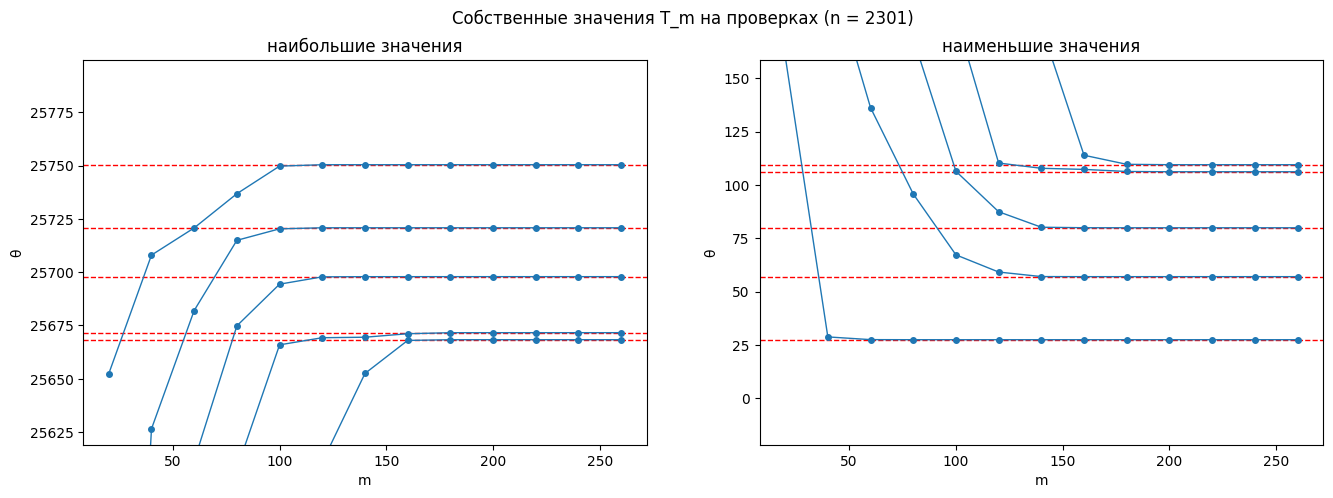

In [16]:
def plot_ritz_history(checks, exact, count, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle(title)

    steps = [m for m in checks if m >= count]

    for ax, side, name in [(axes[0], slice(-count, None), 'наибольшие'), (axes[1], slice(0, count), 'наименьшие')]:
        values = np.array([checks[m].values[side] for m in steps])
        for value in exact[side]:
            ax.axhline(value, color='red', linestyle='--', linewidth=1)
        ax.plot(steps, values, color=sns.color_palette()[0], marker='o', markersize=4, linewidth=1)

        margin = 0.6 * (exact[side].max() - exact[side].min())
        ax.set(title=f'{name} значения', xlabel='m', ylabel='θ', ylim=(exact[side].min() - margin, exact[side].max() + margin))


plot_ritz_history(result.checks, exact, 5, f'Собственные значения T_m на проверках (n = {A.n})')

Наибольшие приближения подходят к собственным значениям снизу, наименьшие - сверху, как и следует из теории. Первыми сходятся самые крайние значения: на графике приближение к $\lambda_{\min}$ неотличимо от точного значения с 60-го шага, к $\lambda_{\max}$ - с сотого. Чем дальше собственное значение от края спектра, тем позже к нему появляется приближение.

Собственные векторы. Вверху - три найденных вектора для наименьших собственных значений, развёрнутые на сетку, внизу - их отличие от аналитических.

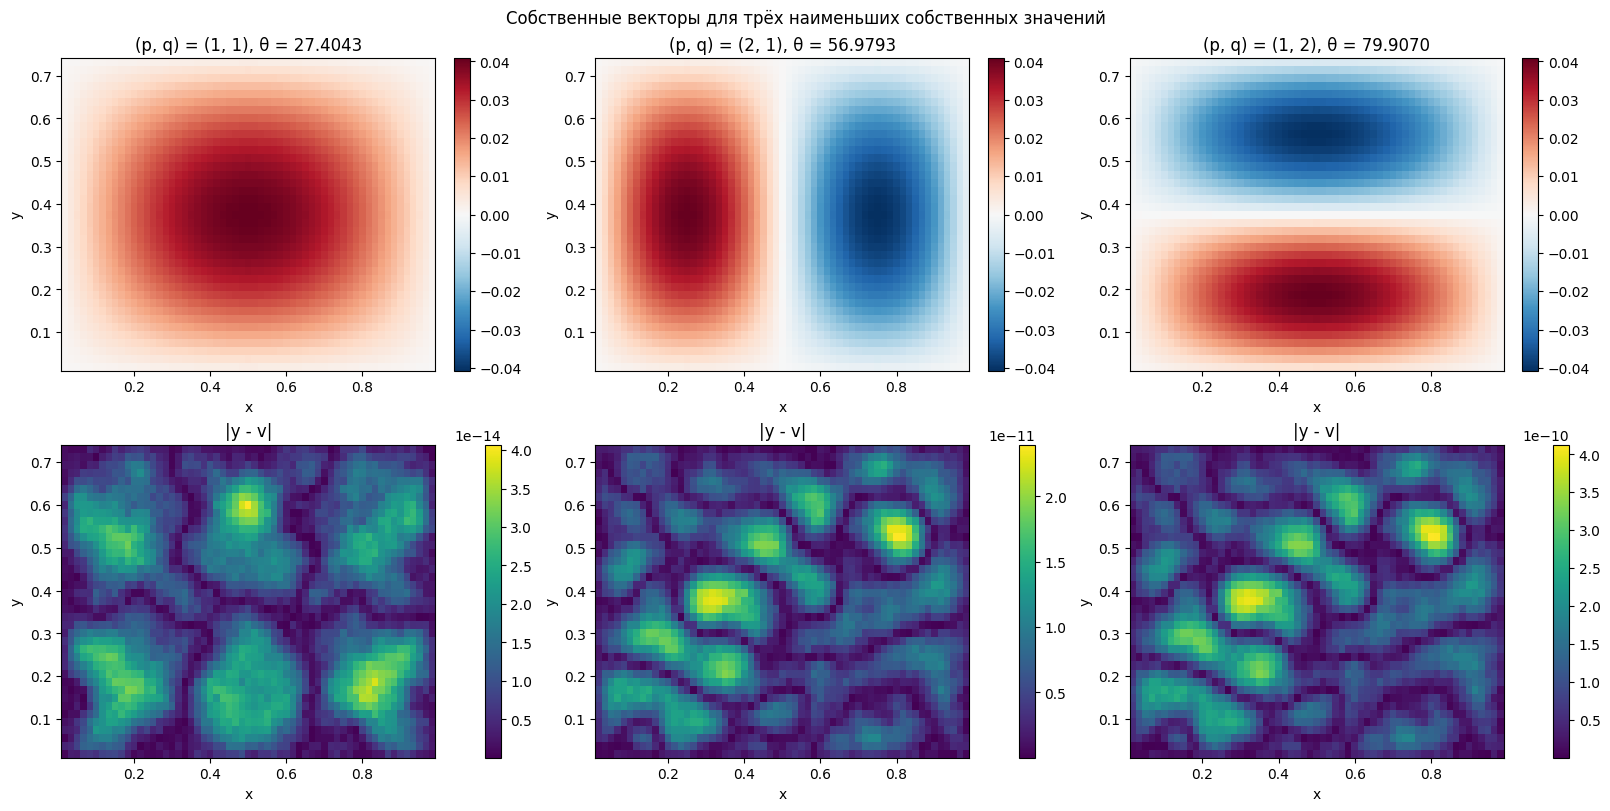

In [17]:
def on_grid(grid, vector):
    return vector.reshape(grid.n_x - 1, grid.n_y - 1)


def aligned(y, v):
    return y if y @ v >= 0 else -y


def plot_vectors(grid, result, pairs, indices, title):
    _, mode_p, mode_q = grid_spectrum(grid)
    x = np.linspace(0, grid.l_x, grid.n_x + 1)[1:-1]
    y = np.linspace(0, grid.l_y, grid.n_y + 1)[1:-1]

    fig, axes = plt.subplots(2, len(indices), figsize=(16, 8), layout='constrained')
    fig.suptitle(title)

    for column, index in enumerate(indices):
        v = grid_eigenvector(grid, mode_p[index], mode_q[index])
        found = aligned(ritz_vector(result, pairs, index), v)
        limit = np.abs(found).max()

        mesh = axes[0, column].pcolormesh(x, y, on_grid(grid, found).T, shading='auto', cmap='RdBu_r', vmin=-limit, vmax=limit)
        fig.colorbar(mesh, ax=axes[0, column])
        axes[0, column].set(title=f'(p, q) = ({mode_p[index]}, {mode_q[index]}), θ = {pairs.values[index]:.4f}', xlabel='x', ylabel='y')

        mesh = axes[1, column].pcolormesh(x, y, np.abs(on_grid(grid, found - v)).T, shading='auto', cmap='viridis')
        fig.colorbar(mesh, ax=axes[1, column])
        axes[1, column].set(title='|y - v|', xlabel='x', ylabel='y')


plot_vectors(grid, result, pairs, [0, 1, 2], 'Собственные векторы для трёх наименьших собственных значений')

Те же векторы в сечении $y = l_y / 4$ и вектор для наибольшего собственного значения. Сплошные линии - найденные векторы, красный пунктир - аналитические.

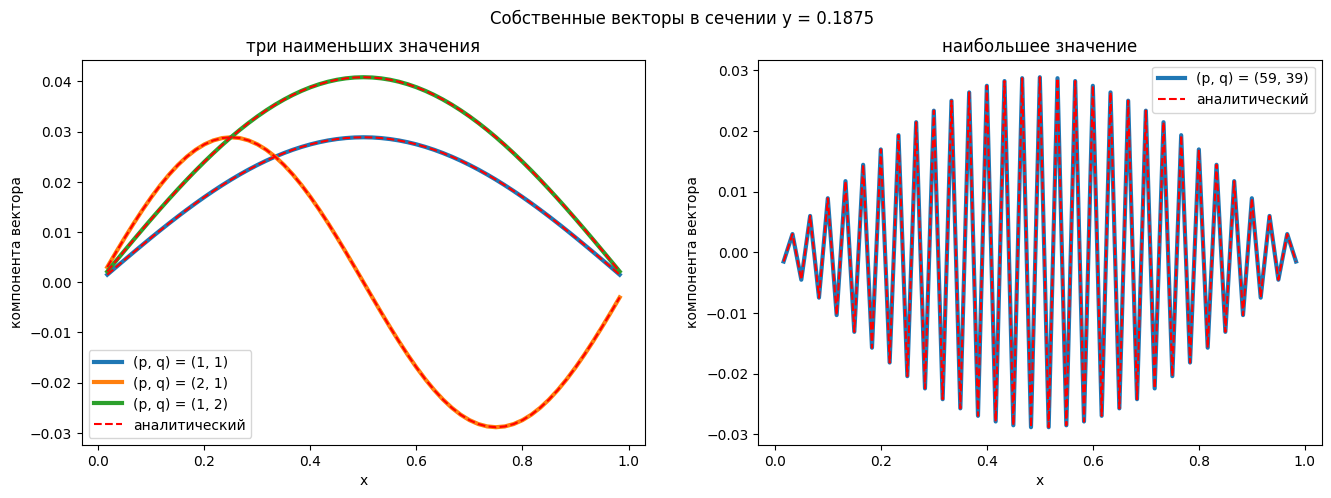

In [18]:
def plot_exact(ax, x, curves):
    for i, curve in enumerate(curves):
        ax.plot(x, curve, color='red', linestyle='--', linewidth=1.5, label='аналитический' if i == 0 else None)
    ax.legend()


def plot_sections(grid, result, pairs):
    _, mode_p, mode_q = grid_spectrum(grid)
    x = np.linspace(0, grid.l_x, grid.n_x + 1)[1:-1]
    j_section = grid.n_y // 4 - 1
    colors = sns.color_palette()

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle(f'Собственные векторы в сечении y = {grid.l_y * (j_section + 1) / grid.n_y:.4f}')

    for ax, indices, name in [(axes[0], [0, 1, 2], 'три наименьших значения'), (axes[1], [-1], 'наибольшее значение')]:
        curves = []
        for index, color in zip(indices, colors):
            v = grid_eigenvector(grid, mode_p[index], mode_q[index])
            found = aligned(ritz_vector(result, pairs, index), v)
            sns.lineplot(x=x, y=on_grid(grid, found)[:, j_section], color=color, linewidth=3, label=f'(p, q) = ({mode_p[index]}, {mode_q[index]})', ax=ax)
            curves.append(on_grid(grid, v)[:, j_section])
        plot_exact(ax, x, curves)
        ax.set(title=name, xlabel='x', ylabel='компонента вектора')


plot_sections(grid, result, pairs)

Найденные векторы совпадают с аналитическими: отличие не больше $4 \cdot 10^{-10}$ при компонентах порядка $0.04$. Вектор для наименьшего собственного значения не меняет знак, у двух следующих по одной линии нулей. Вектор для наибольшего значения меняет знак в каждом узле.

------

# 7. Исследования

## Число шагов

Для каждой проверки основного расчёта возьмём погрешность шести искомых значений $|\theta_i - \lambda_i|$ и оценку невязки $\beta_m|s_{mi}|$. Обе величины делим на $\lambda_{\max}$.

In [19]:
def neighbour_gap(exact, index):
    index = index % len(exact)
    return min(abs(exact[index] - exact[other]) for other in (index - 1, index + 1) if 0 <= other < len(exact))


def convergence_history(checks, exact, labels, count):
    rows = []

    for m, pairs in checks.items():
        if m < 2 * count:
            continue
        for index in [*range(count), *range(-count, 0)]:
            rows.append({
                'm': m,
                '(p, q)': labels[index],
                'конец спектра': 'наименьшие' if index >= 0 else 'наибольшие',
                'погрешность': abs(pairs.values[index] - exact[index]) / exact[-1],
                'оценка невязки': pairs.residuals[index] / exact[-1],
                'зазор до соседнего λ': neighbour_gap(exact, index) / exact[-1],
            })

    return pd.DataFrame(rows)


def plot_convergence(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    fig.suptitle(title)

    for ax, name in zip(axes, ['наибольшие', 'наименьшие']):
        part = history[history['конец спектра'] == name].melt(
            id_vars=['m', '(p, q)'], value_vars=['погрешность', 'оценка невязки'], var_name='величина', value_name='значение')
        sns.lineplot(data=part.replace(0, np.nan), x='m', y='значение', hue='(p, q)', style='величина', markers=True, ax=ax)
        ax.set_yscale('log')
        ax.set(title=f'{name} значения', ylabel='относительно λ_max')


labels = np.array([f'({p}, {q})' for p, q in zip(mode_p, mode_q)])
history = convergence_history(result.checks, exact, labels, wanted)

history.pivot_table(index=['конец спектра', '(p, q)'], columns='m', values='погрешность', sort=False).iloc[:, ::2]

m                            20        60            100           140  \
конец спектра (p, q)                                                     
наименьшие    (1, 1)    0.005173  0.000002  7.768184e-09  3.640438e-12   
              (2, 1)    0.016545  0.003078  3.970190e-04  1.558298e-06   
              (1, 2)    0.044245  0.004966  1.029011e-03  1.000572e-05   
наибольшие    (59, 38)  0.043518  0.003357  1.368308e-04  5.027965e-07   
              (58, 39)  0.017959  0.001507  1.916546e-05  1.192790e-08   
              (59, 39)  0.003806  0.001151  2.528539e-05  2.359547e-09   

m                                180           220           260  
конец спектра (p, q)                                              
наименьшие    (1, 1)    2.727617e-16  8.140080e-18  1.848764e-17  
              (2, 1)    6.363924e-10  1.531549e-14  1.517642e-17  
              (1, 2)    2.254440e-08  1.835964e-12  6.622438e-18  
наибольшие    (59, 38)  1.269481e-10  1.539938e-14  5.651147e-16  
              (58, 39)  7.058283e-13  5.086033e-15  9.889508e-16  
              (59, 39)  3.023364e-14  1.977902e-15  2.684295e-15

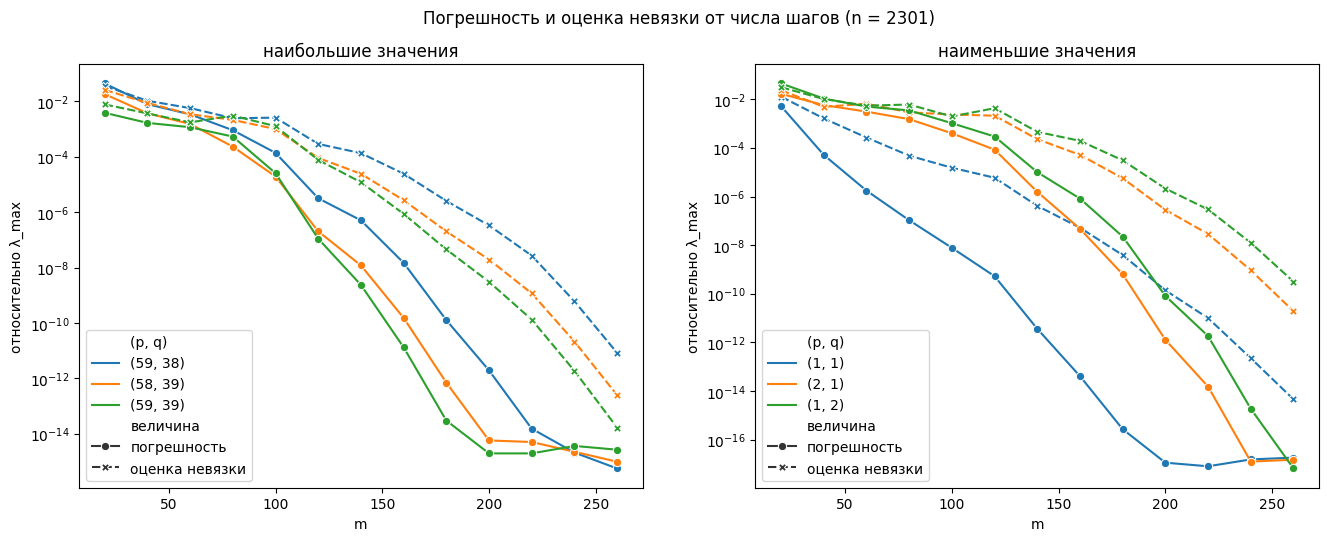

In [20]:
plot_convergence(history, f'Погрешность и оценка невязки от числа шагов (n = {A.n})')

Проверим на всех приближениях свойства, выведенные в теории: рядом с каждым $\theta_i$ есть собственное значение $A$ на расстоянии не больше оценки невязки; $\theta_{\max}$ не убывает и не превосходит $\lambda_{\max}$; $\theta_{\min}$ не возрастает и не меньше $\lambda_{\min}$.

In [21]:
def distance_to_spectrum(values, exact):
    position = np.clip(np.searchsorted(exact, values), 1, len(exact) - 1)
    return np.minimum(np.abs(values - exact[position - 1]), np.abs(values - exact[position]))


bound = max((distance_to_spectrum(pairs_.values, exact) - pairs_.residuals).max() for pairs_ in result.checks.values())
largest = np.array([pairs_.values[-1] for pairs_ in result.checks.values()])
smallest = np.array([pairs_.values[0] for pairs_ in result.checks.values()])
rounding = 1e-12 * exact[-1]

print(f'приближений проверено: {sum(len(pairs_.values) for pairs_ in result.checks.values())}')
print('наибольшее превышение расстояния до спектра над оценкой невязки:', bound)
print('θ_max не убывает:', bool(np.all(np.diff(largest) >= -rounding)), '| θ_max <= λ_max:', bool(np.all(largest <= exact[-1] + rounding)))
print('θ_min не возрастает:', bool(np.all(np.diff(smallest) <= rounding)), '| θ_min >= λ_min:', bool(np.all(smallest >= exact[0] - rounding)))

above_rounding = history[history['погрешность'] > 1e-11]
ratio = above_rounding['погрешность'] * above_rounding['зазор до соседнего λ'] / above_rounding['оценка невязки']**2
print(f'погрешность * зазор до соседнего λ / невязка^2 (где погрешность выше 1e-11): от {ratio.min():.2f} до {ratio.max():.2f}, медиана {ratio.median():.2f}')

приближений проверено: 1820
наибольшее превышение расстояния до спектра над оценкой невязки: -1.1844730301243277e-10
θ_max не убывает: True | θ_max <= λ_max: True
θ_min не возрастает: True | θ_min >= λ_min: True
погрешность * зазор до соседнего λ / невязка^2 (где погрешность выше 1e-11): от 0.01 до 0.45, медиана 0.03


- Сходимость ускоряется с ростом $m$. Погрешность $\lambda_{\max}$ за первые 100 шагов уменьшилась в 150 раз (с $3.8 \cdot 10^{-3}$ до $2.5 \cdot 10^{-5}$), а за следующие 80 - почти в миллиард раз (до $3.0 \cdot 10^{-14}$). К 260-му шагу погрешность всех шести значений не больше $3 \cdot 10^{-15}$ - это уровень ошибок округления.
- Крайние значения сходятся раньше. Погрешность $10^{-8}$ для $\lambda_{\min}$ достигнута на 100-м шаге, для третьего снизу значения - только к 200-му.
- Оценка невязки надёжна: для всех 1820 приближений на 13 проверках расстояние до ближайшего собственного значения не превышает $\beta_m|s_{mi}|$. При этом она с большим запасом: на последней проверке оценки невязки доходят до $3 \cdot 10^{-10}$, а погрешности не больше $3 \cdot 10^{-15}$.
- Наблюдение без вывода: погрешность убывает как квадрат невязки. Величина «погрешность $\cdot$ расстояние до соседнего собственного значения / невязка$^2$» лежит между 0.01 и 0.45.
- $\theta_{\max}$ не убывает и не превосходит $\lambda_{\max}$, $\theta_{\min}$ не возрастает и не меньше $\lambda_{\min}$ - как в теории.

## Сравнение со степенным методом

Степенной метод со скалярными произведениями: $z^{(k)} = Ay^{(k-1)}$, $y^{(k)} = z^{(k)} / \|z^{(k)}\|_2$, $\lambda_1^{(k)} = (y^{(k)}, Ay^{(k)})$. На итерацию тратится одно умножение на матрицу, как и на шаг метода Ланцоша. Запустим его с того же начального вектора на той же матрице и сравним погрешность наибольшего собственного значения при одинаковом числе умножений. Чтобы сравнение было прямым, оба метода оцениваем по отклонению от точного значения.

In [22]:
def power_method(A, y_0, exact_value, tolerance, max_iterations):
    y = y_0 / np.linalg.norm(y_0)
    z = multiply(A, y)
    errors = [abs(y @ z - exact_value)]

    while errors[-1] > tolerance and len(errors) < max_iterations:
        y = z / np.linalg.norm(z)
        z = multiply(A, y)
        errors.append(abs(y @ z - exact_value))

    return np.array(errors)


def first_reached(positions, errors, tolerance):
    reached = np.flatnonzero(errors <= tolerance)
    return positions[reached[0]] if len(reached) else np.nan


power_errors = power_method(A, q_1, exact[-1], 1e-10 * exact[-1], 50_000) / exact[-1]
lanczos_errors = pd.Series({m: abs(pairs_.values[-1] - exact[-1]) / exact[-1] for m, pairs_ in result.checks.items()})
tolerances = [1e-2, 1e-4, 1e-6, 1e-8, 1e-10]

comparison = pd.DataFrame({
    'степенной метод': {tolerance: first_reached(np.arange(1, len(power_errors) + 1), power_errors, tolerance) for tolerance in tolerances},
    'метод Ланцоша': {tolerance: first_reached(lanczos_errors.index.to_numpy(), lanczos_errors.to_numpy(), tolerance) for tolerance in tolerances},
}).rename_axis('относительная погрешность')
comparison['отношение'] = comparison['степенной метод'] / comparison['метод Ланцоша']

print('оценка метода Ланцоша не хуже оценки степенного метода на всех проверках:',
      bool(all(lanczos_errors[m] <= power_errors[m - 1] for m in lanczos_errors.index)))
comparison

оценка метода Ланцоша не хуже оценки степенного метода на всех проверках: True


,степенной метод,метод Ланцоша,отношение
относительная погрешность,,,
1.000000e-02,42,20,2.100000
1.000000e-04,3272,100,32.720000
1.000000e-06,5312,120,44.266667
1.000000e-08,7316,140,52.257143
1.000000e-10,9320,160,58.250000


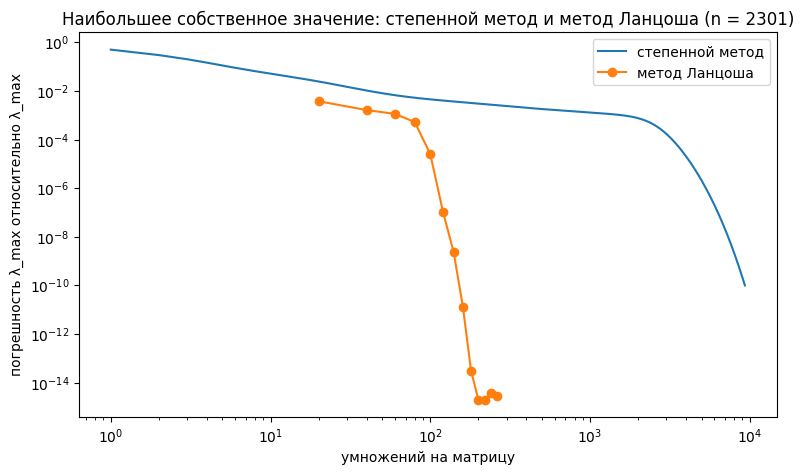

In [23]:
plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(power_errors) + 1), power_errors, label='степенной метод')
plt.plot(lanczos_errors.index, lanczos_errors.values, marker='o', label='метод Ланцоша')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('умножений на матрицу')
plt.ylabel('погрешность λ_max относительно λ_max')
plt.title(f'Наибольшее собственное значение: степенной метод и метод Ланцоша (n = {A.n})')
plt.legend();

Скорость степенного метода задаётся отношением $\lambda_2 / \lambda_1 = 0.99885$, и на относительную погрешность $10^{-8}$ он тратит 7316 умножений на матрицу. Методу Ланцоша хватает 140 (с точностью до 20 шагов между проверками) - в 52 раза меньше. Разрыв растёт с точностью: при $10^{-2}$ он двукратный, при $10^{-10}$ - 58-кратный.

На всех 13 проверках оценка метода Ланцоша не хуже оценки степенного метода при том же числе умножений, как и следует из теории. Причина в том, что метод Ланцоша использует все векторы $A^ky^{(0)}$, а степенной метод - только последний. К тому же степенной метод даёт одно собственное значение, а метод Ланцоша за те же шаги - несколько значений с обоих концов спектра.

## Разделённость спектра

Скорость степенного метода определяется отношением $|\lambda_2 / \lambda_1|$. Посмотрим, от чего зависит скорость метода Ланцоша. Берём диагональные матрицы порядка 5000: все собственные значения, кроме одного, равномерно заполняют отрезок $[0, 1]$, а наибольшее равно $1 + g$. Меру отделённости наибольшего значения назовём зазором:

$
\gamma = \dfrac{\lambda_1 - \lambda_2}{\lambda_1 - \lambda_n} = \dfrac{g}{1 + g}.
$

Для каждого $g$ считаем число шагов метода Ланцоша и число итераций степенного метода до погрешности $10^{-8}$.

In [24]:
size_gap = 5000
tolerance_gap = 1e-8
gap_rows = []

for g in [1, 0.3, 0.1, 0.03, 0.01, 0.003]:
    D = diagonal_matrix(np.r_[np.linspace(0, 1, size_gap - 1), 1 + g])
    start_vector = np.random.default_rng(seed).standard_normal(size_gap)

    run = lanczos(D, start_vector, 300, converged=largest_within(1 + g, tolerance_gap), check_every=1)
    power = power_method(D, start_vector, 1 + g, tolerance_gap, 100_000)
    gap_rows.append({'g': g, 'зазор': g / (1 + g), 'метод Ланцоша': len(run.alphas), 'степенной метод': len(power)})

gap_study = pd.DataFrame(gap_rows)
gap_slopes = {
    name: np.polyfit(np.log(gap_study['зазор']), np.log(gap_study[name]), 1)[0]
    for name in ['метод Ланцоша', 'степенной метод']
}

print('показатель степени в зависимости "число шагов ~ зазор^p":', {name: round(slope, 2) for name, slope in gap_slopes.items()})
gap_study.assign(отношение=gap_study['степенной метод'] / gap_study['метод Ланцоша']).set_index('g')

показатель степени в зависимости "число шагов ~ зазор^p": {'метод Ланцоша': np.float64(-0.43), 'степенной метод': np.float64(-0.9)}


,зазор,метод Ланцоша,степенной метод,отношение
g,,,,
1.000,0.500000,9,17,1.888889
0.300,0.230769,14,40,2.857143
0.100,0.090909,21,97,4.619048
0.030,0.029126,33,267,8.090909
0.010,0.009901,52,668,12.846154
0.003,0.002991,83,1791,21.578313


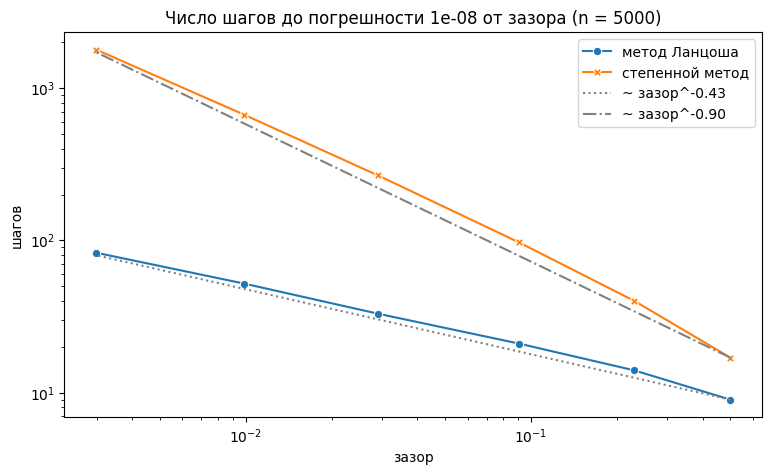

In [25]:
plt.figure(figsize=(9, 5))
ax = sns.lineplot(data=gap_study.melt(id_vars=['g', 'зазор'], var_name='метод', value_name='шагов'), x='зазор', y='шагов', hue='метод', style='метод', markers=True, dashes=False)

for (name, slope), linestyle in zip(gap_slopes.items(), [':', '-.']):
    anchor = gap_study.iloc[0]
    ax.plot(gap_study['зазор'], anchor[name] * (gap_study['зазор'] / anchor['зазор']) ** slope, color='gray', linestyle=linestyle, label=f'~ зазор^{slope:.2f}')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(f'Число шагов до погрешности {tolerance_gap:g} от зазора (n = {size_gap})')
ax.legend();

Чем меньше зазор, тем больше шагов нужно обоим методам, но растёт их число по-разному. При уменьшении зазора в 167 раз (с 0.5 до 0.003) число итераций степенного метода выросло в 105 раз (с 17 до 1791), а число шагов метода Ланцоша - в 9 раз (с 9 до 83).

Подгонка степенной зависимостью даёт показатель $-0.90$ для степенного метода и $-0.43$ для метода Ланцоша. То есть число шагов метода Ланцоша растёт примерно как корень из обратного зазора. Теоретической оценки этого показателя у нас нет, это результат эксперимента.

## Размерность матрицы

Сеточные матрицы на сетках от $20 \times 15$ до $100 \times 70$. Для каждой считаем число шагов, за которое наибольшее приближение подходит к $\lambda_{\max}$ с относительной погрешностью $10^{-8}$ (проверка каждые 10 шагов), и зазор $\gamma$ для $\lambda_{\max}$.

In [26]:
grids = [Grid(20, 15), Grid(40, 30), Grid(60, 40), Grid(80, 60), Grid(100, 70)]
dimension_rows = []

for grid_ in grids:
    A_ = grid_matrix(grid_)
    exact_ = grid_spectrum(grid_)[0]
    start_vector = np.random.default_rng(seed).standard_normal(A_.n)

    start = time.perf_counter()
    run = lanczos(A_, start_vector, 400, converged=largest_within(exact_[-1], 1e-8 * exact_[-1]), check_every=10)
    with_checks = time.perf_counter() - start

    start = time.perf_counter()
    lanczos(A_, start_vector, len(run.alphas))
    steps_only = time.perf_counter() - start

    dimension_rows.append({
        'сетка': f'{grid_.n_x} x {grid_.n_y}',
        'n': A_.n,
        'ненулевых': len(A_.values),
        'зазор': (exact_[-1] - exact_[-2]) / (exact_[-1] - exact_[0]),
        'шагов': len(run.alphas),
        'шагов / n_x': len(run.alphas) / grid_.n_x,
        'время шагов, с': steps_only,
        'время с проверками, с': with_checks,
    })

dimension_study = pd.DataFrame(dimension_rows)
dimension_slope = np.polyfit(np.log(dimension_study['n']), np.log(dimension_study['шагов']), 1)[0]
dimension_gap_slope = np.polyfit(np.log(dimension_study['зазор']), np.log(dimension_study['шагов']), 1)[0]

print(f'число шагов ~ n^{dimension_slope:.2f}, число шагов ~ зазор^{dimension_gap_slope:.2f}')
dimension_study.set_index('сетка')

число шагов ~ n^0.43, число шагов ~ зазор^-0.44


,n,ненулевых,зазор,шагов,шагов / n_x,"время шагов, с","время с проверками, с"
сетка,,,,,,,
20 x 15,266,1264,0.009317,50,2.500000,0.000732,0.103560
40 x 30,1131,5519,0.002317,90,2.250000,0.003301,0.566226
60 x 40,2301,11309,0.001150,140,2.333333,0.010464,2.332476
80 x 60,4661,23029,0.000579,170,2.125000,0.022718,4.444218
100 x 70,6831,33819,0.000396,200,2.000000,0.036670,7.761435


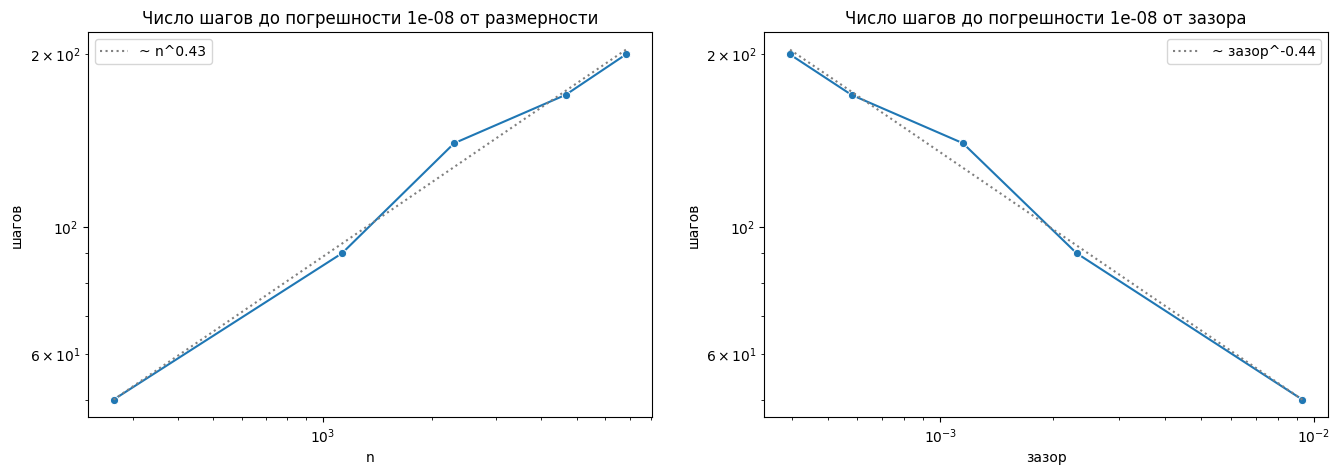

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, column, slope in [(axes[0], 'n', dimension_slope), (axes[1], 'зазор', dimension_gap_slope)]:
    sns.lineplot(data=dimension_study, x=column, y='шагов', marker='o', ax=ax)
    anchor = dimension_study.iloc[0]
    ax.plot(dimension_study[column], anchor['шагов'] * (dimension_study[column] / anchor[column]) ** slope, color='gray', linestyle=':', label=f'~ {column}^{slope:.2f}')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f'Число шагов до погрешности 1e-08 от {"размерности" if column == "n" else "зазора"}')
    ax.legend()

С ростом размерности крайние собственные значения сеточной матрицы сближаются: зазор для $\lambda_{\max}$ падает с $9.3 \cdot 10^{-3}$ до $4.0 \cdot 10^{-4}$. Число шагов растёт с 50 до 200, примерно как $n^{0.43}$, то есть близко к $\sqrt{n}$: отношение числа шагов к $n_x$ остаётся в пределах 2.0-2.5.

Зависимость от зазора почти та же, что на диагональных матрицах: показатель $-0.44$ против $-0.43$. Похоже, что число шагов растёт в основном из-за сужения зазора, а не из-за самой размерности. Проверим это прямо.

**Тот же спектр, разная размерность.** Берём диагональные матрицы с одинаковым устройством спектра - значения равномерно заполняют $[0, 1]$, наибольшее равно $1 + g$ - и порядком от 500 до 500 000. Зазор при этом один и тот же.

У случайного вектора единичной длины составляющая по одному собственному вектору порядка $1 / \sqrt{n}$. Чтобы проверить, не в ней ли дело, добавим третий расчёт: порядок матрицы фиксирован, $n = 5000$, а составляющая начального вектора по искомому собственному вектору задана равной $1 / \sqrt{n'}$ для тех же $n'$ от 500 до 500 000.

In [28]:
sizes_same = [500, 5000, 50_000, 500_000]
same_rows = []

for g in [0.1, 0.03]:
    for size_ in sizes_same:
        D = diagonal_matrix(np.r_[np.linspace(0, 1, size_ - 1), 1 + g])
        start_vector = np.random.default_rng(seed).standard_normal(size_)
        run = lanczos(D, start_vector, 150, converged=largest_within(1 + g, tolerance_gap), check_every=1)
        same_rows.append({'n': size_, 'расчёт': f'порядок матрицы n, g = {g}', 'шагов': len(run.alphas)})

D = diagonal_matrix(np.r_[np.linspace(0, 1, size_gap - 1), 1.03])
for size_ in sizes_same:
    start_vector = np.random.default_rng(seed).standard_normal(size_gap)
    component = 1 / np.sqrt(size_)
    start_vector[:-1] *= np.sqrt(1 - component**2) / np.linalg.norm(start_vector[:-1])
    start_vector[-1] = component

    run = lanczos(D, start_vector, 150, converged=largest_within(1.03, tolerance_gap), check_every=1)
    same_rows.append({'n': size_, 'расчёт': 'порядок 5000, g = 0.03, составляющая 1/√n', 'шагов': len(run.alphas)})

same_study = pd.DataFrame(same_rows)
same_study.pivot(index='расчёт', columns='n', values='шагов')

n,500,5000,50000,500000
расчёт,,,,
"порядок 5000, g = 0.03, составляющая 1/√n",32,35,39,42
"порядок матрицы n, g = 0.03",35,33,39,42
"порядок матрицы n, g = 0.1",22,21,24,25


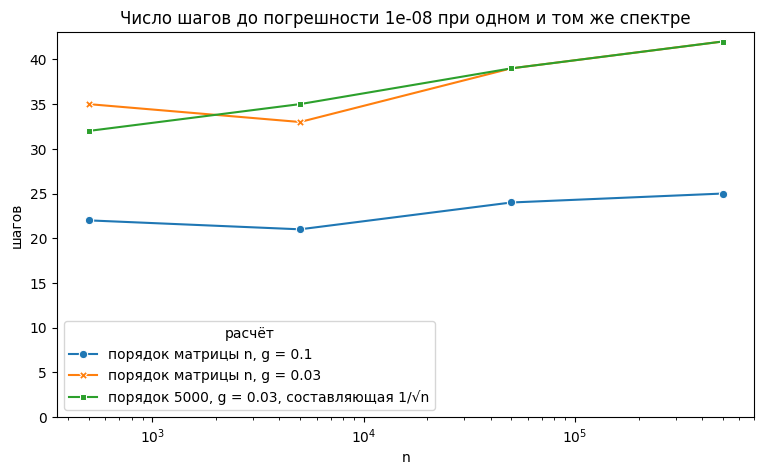

In [29]:
plt.figure(figsize=(9, 5))
ax = sns.lineplot(data=same_study, x='n', y='шагов', hue='расчёт', style='расчёт', markers=True, dashes=False)
ax.set_xscale('log')
ax.set_ylim(0)
ax.set_title(f'Число шагов до погрешности {tolerance_gap:g} при одном и том же спектре');

При одном и том же спектре число шагов всё же растёт с размерностью, но слабо. При увеличении порядка в 1000 раз оно выросло с 35 до 42 при $g = 0.03$ и с 22 до 25 при $g = 0.1$ - это от одного до трёх шагов на каждое увеличение размерности в 10 раз.

Третий расчёт показывает причину. При фиксированном порядке 5000 число шагов меняется так же - 32, 35, 39, 42, - если уменьшать только составляющую начального вектора по искомому собственному вектору. Значит, размерность влияет через начальный вектор: чем больше $n$, тем меньше у случайного вектора составляющая по нужному направлению и тем больше шагов нужно, чтобы её выделить. При $n = 500$ и $n = 5000$ число шагов почти одинаково (35 и 33): у конкретного случайного вектора составляющая может оказаться и больше, и меньше, чем $1 / \sqrt{n}$.

Итог: главный фактор - разделённость спектра. Уменьшение зазора в 167 раз увеличило число шагов в 9 раз, а увеличение размерности в 1000 раз при том же спектре - на 14-20 %.

Для сеточной матрицы порядка $10^6$ по зависимости от зазора нужно около двух тысяч шагов. Для нашей реализации это слишком много: малая задача для $T_m$ при таком $m$ решается методом вращений слишком долго.

## Начальный вектор

Сначала пять случайных начальных векторов на основной матрице: сравним погрешность крайних значений после 120 шагов.

In [30]:
seed_rows = {}

for seed_ in range(5):
    run = lanczos(A, np.random.default_rng(seed_).standard_normal(A.n), 120)
    pairs_ = ritz_pairs(run)
    seed_rows[seed_] = {
        'погрешность λ_max': (exact[-1] - pairs_.values[-1]) / exact[-1],
        'погрешность λ_min': (pairs_.values[0] - exact[0]) / exact[-1],
    }

pd.DataFrame(seed_rows).T.rename_axis('начальный вектор')

,погрешность λ_max,погрешность λ_min
начальный вектор,,
0,1.095608e-07,5.293714e-10
1,4.209104e-09,1.874392e-09
2,5.425651e-09,3.037313e-12
3,7.911116e-10,1.156450e-09
4,7.564586e-09,1.246779e-09


Теперь возьмём вектор из единиц, $q_1 = (1, \ldots, 1)^T / \sqrt{n}$, и сделаем 150 шагов. Для пяти наименьших приближений найдём ближайшие точные собственные значения.

In [31]:
ones_result = lanczos(A, np.ones(A.n), 150)
ones_pairs = ritz_pairs(ones_result)

position = np.abs(exact[None, :] - ones_pairs.values[:5, None]).argmin(axis=1)

pd.DataFrame({
    'θ': ones_pairs.values[:5],
    'оценка невязки': ones_pairs.residuals[:5],
    'ближайшее λ': exact[position],
    '(p, q)': labels[position],
    'номер λ по возрастанию': position + 1,
})

,θ,оценка невязки,ближайшее λ,"(p, q)",номер λ по возрастанию
0,27.404296,1.729734e-10,27.404296,"(1, 1)",1
1,106.180894,6.291799e-10,106.180894,"(3, 1)",4
2,167.051803,1.070387e-08,167.051803,"(1, 3)",7
3,245.828401,2.358218e-06,245.828401,"(3, 3)",11
4,262.870997,2.237930e-06,262.870997,"(5, 1)",12


Для сравнения - пять наименьших собственных значений матрицы и скалярные произведения начального вектора $q_1 = (1, \ldots, 1)^T / \sqrt{n}$ с их собственными векторами:

In [32]:
unit_ones = np.ones(A.n) / np.sqrt(A.n)

pd.DataFrame({
    '(p, q)': labels[:5],
    'λ': exact[:5],
    '(q_1, v)': [unit_ones @ grid_eigenvector(grid, mode_p[index], mode_q[index]) for index in range(5)],
}, index=pd.Index(range(1, 6), name='номер λ по возрастанию'))

,"(p, q)",λ,"(q_1, v)"
номер λ по возрастанию,,,
1,"(1, 1)",27.404296,8.272085e-01
2,"(2, 1)",56.979299,7.068321e-17
3,"(1, 2)",79.907012,1.725914e-17
4,"(3, 1)",106.180894,2.752319e-01
5,"(2, 2)",109.482016,4.336809e-19


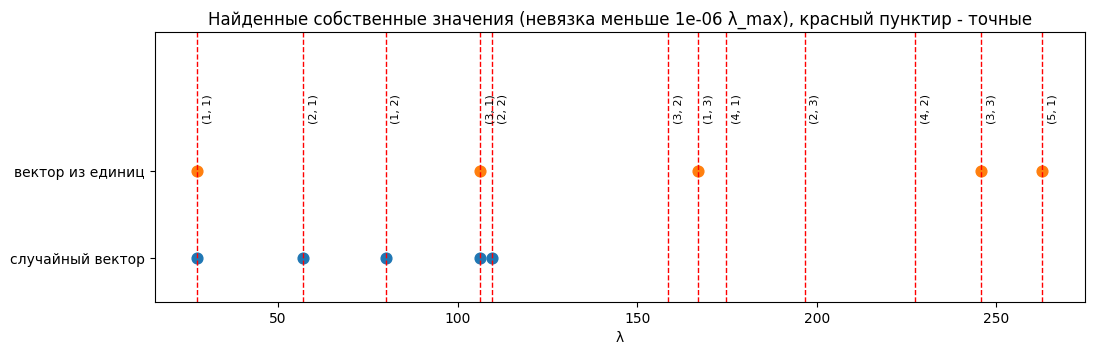

In [33]:
def converged_values(pairs, tolerance):
    return pairs.values[pairs.residuals <= tolerance]


upper_bound = 280
found_values = {
    'случайный вектор': converged_values(pairs, 1e-6 * exact[-1]),
    'вектор из единиц': converged_values(ones_pairs, 1e-6 * exact[-1]),
}

plt.figure(figsize=(12, 3.5))
for value, label in zip(exact[exact < upper_bound], labels[exact < upper_bound]):
    plt.axvline(value, color='red', linestyle='--', linewidth=1)
    plt.text(value + 1.5, 1.55, label, rotation=90, ha='left', va='bottom', fontsize=8)
for row, (name, values) in enumerate(found_values.items()):
    values = values[values < upper_bound]
    plt.scatter(values, np.full(len(values), row), s=60, label=name)
plt.yticks([0, 1], list(found_values))
plt.ylim(-0.5, 2.6)
plt.xlabel('λ')
plt.title('Найденные собственные значения (невязка меньше 1e-06 λ_max), красный пунктир - точные');

Со случайными начальными векторами погрешность после 120 шагов меняется в пределах двух-трёх порядков: для $\lambda_{\max}$ - от $8 \cdot 10^{-10}$ до $1 \cdot 10^{-7}$, для $\lambda_{\min}$ - от $3 \cdot 10^{-12}$ до $2 \cdot 10^{-9}$. Она зависит от того, велика ли составляющая начального вектора по нужному собственному вектору.

С вектором из единиц картина другая. Среди приближений нет второго и третьего собственных значений, $\lambda_{21} = 56.979$ и $\lambda_{12} = 79.907$: найдены только значения с нечётными $p$ и $q$. Причина - вектор из единиц ортогонален собственным векторам с чётным $p$ или $q$: скалярные произведения с ними равны нулю с точностью до округления.

Если $(q_1, x) = 0$ для собственного вектора $x$, то $(A^kq_1, x) = (q_1, A^kx) = \lambda^k(q_1, x) = 0$. Все векторы процесса ортогональны $x$, и соответствующее собственное значение найти нельзя. Поэтому начальный вектор берём случайным.

## Кратные собственные значения

У сеточной матрицы на квадрате с $n_x = n_y$ собственные значения $\lambda_{pq}$ и $\lambda_{qp}$ совпадают. Возьмём сетку $20 \times 20$ на единичном квадрате: второе сверху собственное значение у неё двукратное, $\lambda_{19,18} = \lambda_{18,19}$. Посмотрим, сколько приближений оказывается рядом с ним.

In [34]:
square = Grid(20, 20, 1, 1)
A_square = grid_matrix(square)
exact_square, p_square, q_square = grid_spectrum(square)
q_square_start = np.random.default_rng(seed).standard_normal(A_square.n)

square_result = lanczos(A_square, q_square_start, 200, converged=lambda pairs: False, check_every=20)
double = exact_square[-2]

print('четыре наибольших собственных значения:', exact_square[-4:].round(6))

square_table = pd.DataFrame([
    {
        'm': m,
        'приближений рядом с двукратным значением': int(np.sum(np.abs(pairs_.values - double) <= 1e-6 * exact_square[-1])),
        'θ, третье сверху': pairs_.values[-3],
        'θ, второе сверху': pairs_.values[-2],
    }
    for m, pairs_ in square_result.checks.items() if m >= 40
]).set_index('m')
square_table.style.format({'θ, третье сверху': '{:.8f}', 'θ, второе сверху': '{:.8f}'})

четыре наибольших собственных значения: [3121.690426 3150.995886 3150.995886 3180.301345]


,приближений рядом с двукратным значением,"θ, третье сверху","θ, второе сверху"
m,,,
40,0,3104.53480756,3150.92743889
60,1,3121.68999627,3150.99588538
80,1,3121.69042607,3150.99588551
100,1,3121.69042607,3150.99588551
120,2,3150.99588540,3150.99588551
140,2,3150.99588551,3150.99588551
160,2,3150.99588551,3150.99588551
180,2,3150.99588551,3150.99588551
200,2,3150.99588551,3150.99588551


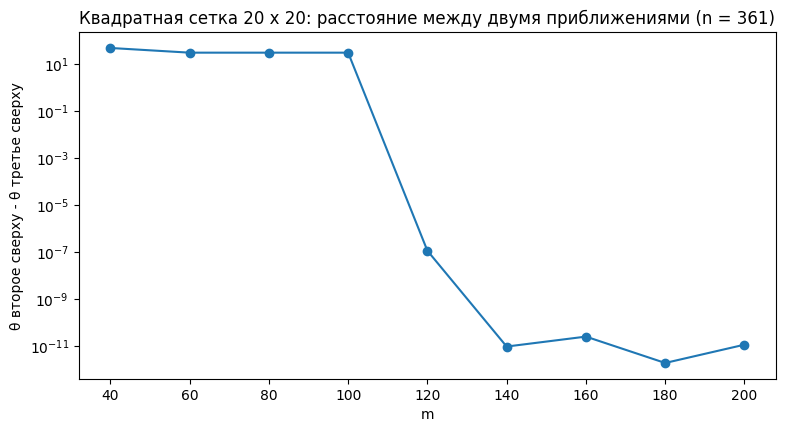

In [35]:
plt.figure(figsize=(9, 4.5))
distance = np.maximum(square_table['θ, второе сверху'] - square_table['θ, третье сверху'], 1e-13)
plt.plot(square_table.index, distance, marker='o')
plt.yscale('log')
plt.xlabel('m')
plt.ylabel('θ второе сверху - θ третье сверху')
plt.title(f'Квадратная сетка 20 x 20: расстояние между двумя приближениями (n = {A_square.n})');

Найденный вектор должен лежать в двумерном собственном подпространстве. Сравним его с проекцией начального вектора на это подпространство:

In [36]:
pairs_100 = square_result.checks[100]
found = ritz_vector(square_result, pairs_100, -2)

v_1 = grid_eigenvector(square, p_square[-2], q_square[-2])
v_2 = grid_eigenvector(square, p_square[-3], q_square[-3])
projection = (q_square_start @ v_1) * v_1 + (q_square_start @ v_2) * v_2
projection /= np.linalg.norm(projection)

print(f'собственные векторы подпространства: ({p_square[-2]}, {q_square[-2]}) и ({p_square[-3]}, {q_square[-3]})')
print('коэффициенты найденного вектора по ним:', round(float(found @ v_1), 6), round(float(found @ v_2), 6))
print('отличие от нормированной проекции начального вектора:', min(np.linalg.norm(found - projection), np.linalg.norm(found + projection)))

second_result = lanczos(A_square, np.random.default_rng(seed + 1).standard_normal(A_square.n), 100)
second = ritz_vector(second_result, ritz_pairs(second_result), -2)
print('второй запуск, другой начальный вектор: коэффициенты', round(float(second @ v_1), 6), round(float(second @ v_2), 6))
print('определитель из коэффициентов двух найденных векторов:', round(float((found @ v_1) * (second @ v_2) - (found @ v_2) * (second @ v_1)), 4))

собственные векторы подпространства: (19, 18) и (18, 19)
коэффициенты найденного вектора по ним: 0.948314 0.317334
отличие от нормированной проекции начального вектора: 1.2985045608575033e-13


второй запуск, другой начальный вектор: коэффициенты 0.242787 0.97008
определитель из коэффициентов двух найденных векторов: 0.8429


Двукратному собственному значению $3150.996$ с 60-го по 100-й шаг отвечает одно приближение, хотя собственных векторов у него два. Найденный вектор - нормированная проекция начального вектора на собственное подпространство: отличие $1.3 \cdot 10^{-13}$.

Так и должно быть. Составляющая $q_1$ в собственном подпространстве - это один вектор $g$, и вектор $A^kq_1$ содержит из этого подпространства только $\lambda^kg$. Метод «видит» кратное значение как простое и находит один вектор.

Вторая копия появляется между 100-м и 120-м шагами (проверки идут каждые 20 шагов). В точной арифметике её бы не было: её порождают ошибки округления, которые вносят в векторы процесса малую составляющую, ортогональную $g$. Рассчитывать на это нельзя.

Надёжный способ найти второй вектор - повторный запуск с другим начальным вектором. Он даёт другой вектор того же подпространства: определитель из коэффициентов двух найденных векторов равен $0.84$, то есть они линейно независимы и вместе задают всё собственное подпространство.

## Потеря ортогональности

Диагональная матрица порядка 2000: собственные значения равномерно заполняют $[0, 1]$, и ещё три отделены - $2$, $2.5$ и $3$. Делаем 100 шагов без переортогонализации и с ней. Ортогональность измеряем величиной $\max|Q_m^TQ_m - E|$.

In [37]:
size_loss = 2000
outliers = [2, 2.5, 3]
D_loss = diagonal_matrix(np.r_[np.linspace(0, 1, size_loss - 3), outliers])
start_vector = np.random.default_rng(seed).standard_normal(size_loss)

loss_runs = {
    'без переортогонализации': lanczos(D_loss, start_vector, 100, reorthogonalize=False, converged=lambda pairs: False, check_every=10),
    'с переортогонализацией': lanczos(D_loss, start_vector, 100, converged=lambda pairs: False, check_every=10),
}


def orthogonality_loss(result):
    steps = len(result.alphas)
    gram = result.Q[:steps] @ result.Q[:steps].T - np.eye(steps)
    return np.array([np.abs(gram[:m, :m]).max() for m in range(1, steps + 1)])


loss = pd.concat([
    pd.DataFrame({'m': np.arange(1, 101), 'max |Q^T Q - E|': orthogonality_loss(run), 'вариант': name})
    for name, run in loss_runs.items()
])

copies = pd.DataFrame([
    {'m': m, 'вариант': name, 'собственное значение': f'λ = {value}', 'приближений': int(np.sum(np.abs(pairs_.values - value) <= 1e-6))}
    for name, run in loss_runs.items()
    for m, pairs_ in run.checks.items()
    for value in outliers
])
copies.pivot(index='m', columns=['вариант', 'собственное значение'], values='приближений')

вариант              без переортогонализации                \
собственное значение                   λ = 2 λ = 2.5 λ = 3   
m                                                            
10                                         0       1     1   
20                                         1       1     1   
30                                         1       1     2   
40                                         2       2     2   
50                                         2       2     3   
60                                         2       3     3   
70                                         3       3     4   
80                                         3       4     4   
90                                         4       4     5   
100                                        4       5     5   

вариант              с переортогонализацией                
собственное значение                  λ = 2 λ = 2.5 λ = 3  
m                                                          
10                                        0       1     1  
20                                        1       1     1  
30                                        1       1     1  
40                                        1       1     1  
50                                        1       1     1  
60                                        1       1     1  
70                                        1       1     1  
80                                        1       1     1  
90                                        1       1     1  
100                                       1       1     1

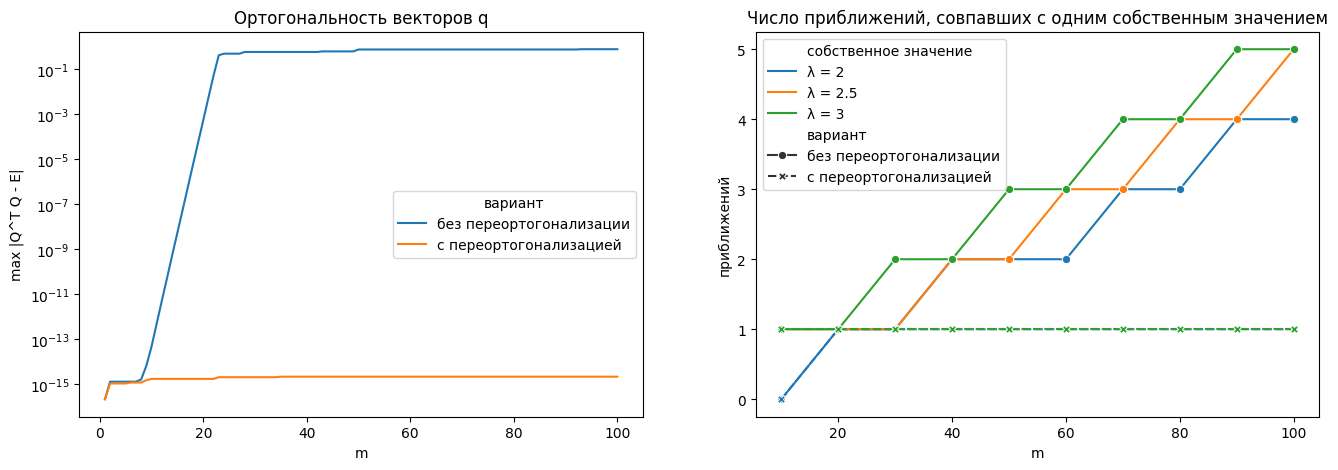

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(data=loss, x='m', y='max |Q^T Q - E|', hue='вариант', ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Ортогональность векторов q')

sns.lineplot(data=copies, x='m', y='приближений', hue='собственное значение', style='вариант', markers=True, ax=axes[1])
axes[1].set_title('Число приближений, совпавших с одним собственным значением');

In [39]:
first_converged = {
    name: next(m for m, pairs_ in run.checks.items() if pairs_.residuals[-1] <= 1e-8)
    for name, run in loss_runs.items()
}
last_pairs = loss_runs['без переортогонализации'].checks[100]
distances = np.abs(last_pairs.values[:, None] - np.array(outliers)[None, :]).min(axis=1)
loss_values = loss[loss['вариант'] == 'без переортогонализации'].set_index('m')['max |Q^T Q - E|']

print('первая проверка, на которой невязка для λ = 3 меньше 1e-08:', first_converged)
print('без переортогонализации, max |Q^T Q - E| при m = 8, 15, 20, 25:', [float(f'{loss_values[m]:.1e}') for m in (8, 15, 20, 25)])
print('с переортогонализацией, наибольшее значение max |Q^T Q - E|:', float(f"{loss[loss['вариант'] == 'с переортогонализацией']['max |Q^T Q - E|'].max():.1e}"))
print(f'без переортогонализации, m = 100: приближений, совпавших с тремя отделёнными значениями: {int(np.sum(distances <= 1e-6))}, их наибольшая погрешность: {distances[distances <= 1e-6].max():.1e}')

первая проверка, на которой невязка для λ = 3 меньше 1e-08: {'без переортогонализации': 20, 'с переортогонализацией': 20}
без переортогонализации, max |Q^T Q - E| при m = 8, 15, 20, 25: [1.7e-15, 5.5e-09, 0.00054, 0.48]
с переортогонализацией, наибольшее значение max |Q^T Q - E|: 2.2e-15
без переортогонализации, m = 100: приближений, совпавших с тремя отделёнными значениями: 14, их наибольшая погрешность: 3.4e-11


Без переортогонализации ортогональность держится на уровне $10^{-15}$ только первые 8 шагов, а затем быстро теряется: $5.5 \cdot 10^{-9}$ на 15-м шаге, $5.4 \cdot 10^{-4}$ на 20-м и $0.48$ на 25-м. По времени это совпадает со сходимостью первых приближений: невязка для $\lambda = 3$ становится меньше $10^{-8}$ между 10-м и 20-м шагами.

После потери ортогональности процесс находит те же собственные значения заново. К 100-му шагу у $\lambda = 3$ и $\lambda = 2.5$ по пять копий, у $\lambda = 2$ - четыре. Сами значения при этом верны: погрешность всех 14 копий не больше $3.4 \cdot 10^{-11}$. Но кратность определить нельзя: простое собственное значение выглядит как пятикратное.

С полной переортогонализацией ортогональность остаётся на уровне $2 \cdot 10^{-15}$, и у каждого значения одна копия. Цена - хранение всех векторов $q_j$ и дополнительные операции на каждом шаге.

## Время и память

Сеточные матрицы на квадратных сетках до $1000 \times 1000$ ($n \approx 10^6$). Измеряем время 30 шагов процесса с переортогонализацией и без неё, а память под разреженную матрицу сравниваем с памятью под плотную ($8n^2$ байт).

In [40]:
steps_time = 30
time_rows = []

for size in [100, 200, 400, 700, 1000]:
    A_ = grid_matrix(Grid(size, size, 1, 1))
    start_vector = np.random.default_rng(seed).standard_normal(A_.n)
    row = {'n': A_.n, 'ненулевых': len(A_.values), 'память, МБ': memory(A_) / 2**20, 'плотная матрица, ГБ': 8 * A_.n**2 / 2**30}

    for name, reorthogonalize in [('с переортогонализацией, с', True), ('без переортогонализации, с', False)]:
        start = time.perf_counter()
        lanczos(A_, start_vector, steps_time, reorthogonalize=reorthogonalize)
        row[name] = time.perf_counter() - start

    time_rows.append(row)
    del A_

time_study = pd.DataFrame(time_rows)
time_study.set_index('n')

,ненулевых,"память, МБ","плотная матрица, ГБ","с переортогонализацией, с","без переортогонализации, с"
n,,,,,
9801,48609,1.187355,0.715700,0.007633,0.007530
39601,197209,4.815895,11.684293,0.028285,0.026350
159201,794409,19.397194,188.834655,0.137721,0.104357
488601,2440209,59.579689,1778.684089,0.389222,0.338437
998001,4986009,121.734840,7420.822948,0.797409,0.714646


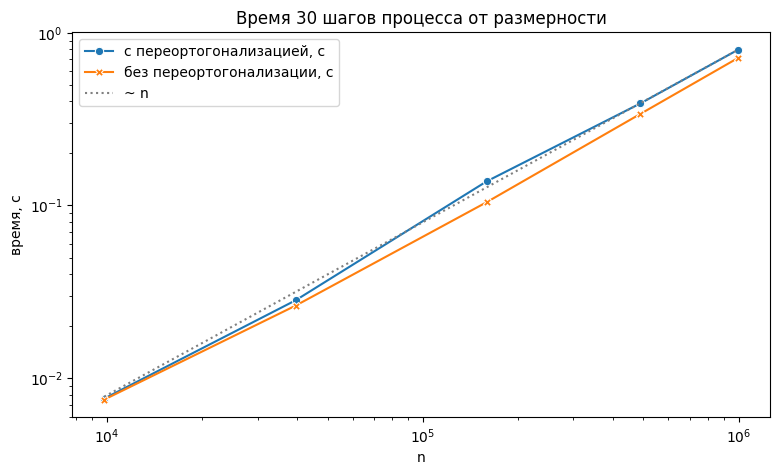

In [41]:
plt.figure(figsize=(9, 5))
melted = time_study.melt(id_vars='n', value_vars=['с переортогонализацией, с', 'без переортогонализации, с'], var_name='вариант', value_name='время, с')
ax = sns.lineplot(data=melted, x='n', y='время, с', hue='вариант', style='вариант', markers=True, dashes=False)
ax.plot(time_study['n'], time_study['с переортогонализацией, с'].iloc[-1] * time_study['n'] / time_study['n'].iloc[-1], color='gray', linestyle=':', label='~ n')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(f'Время {steps_time} шагов процесса от размерности')
ax.legend();

Для сравнения - время плотного решателя `np.linalg.eigvalsh` на тех же сеточных матрицах, что в исследовании размерности. Он находит все $n$ собственных значений, но требует матрицу целиком.

In [42]:
dense_rows = []

for grid_, lanczos_row in zip(grids[:4], dimension_rows):
    dense = to_dense(grid_matrix(grid_))
    start = time.perf_counter()
    np.linalg.eigvalsh(dense)
    dense_rows.append({
        'сетка': lanczos_row['сетка'],
        'n': lanczos_row['n'],
        'плотная матрица, МБ': dense.nbytes / 2**20,
        'eigvalsh, с': time.perf_counter() - start,
        'метод Ланцоша, шагов': lanczos_row['шагов'],
        'шаги процесса, с': lanczos_row['время шагов, с'],
        'с проверками, с': lanczos_row['время с проверками, с'],
    })
    del dense

pd.DataFrame(dense_rows).set_index('сетка')

,n,"плотная матрица, МБ","eigvalsh, с","метод Ланцоша, шагов","шаги процесса, с","с проверками, с"
сетка,,,,,,
20 x 15,266,0.539825,0.002082,50,0.000732,0.103560
40 x 30,1131,9.759224,0.049823,90,0.003301,0.566226
60 x 40,2301,40.394600,0.383569,140,0.010464,2.332476
80 x 60,4661,165.747993,4.606005,170,0.022718,4.444218


Время шагов процесса растёт пропорционально размерности: точки на графике ложатся вдоль прямой $\sim n$. Для матрицы порядка $10^6$ с 5 млн ненулевых элементов 30 шагов заняли в этом запуске 0.8 с, без переортогонализации - 0.7 с. При 30 шагах переортогонализация добавляет около 10 %. С ростом числа шагов её доля растёт, потому что на шаге $j$ вычитается $j$ проекций.

Разреженная матрица порядка $10^6$ занимает 122 МБ, плотная заняла бы 7421 ГБ.

Плотному решателю нужна вся матрица, и его время растёт намного быстрее размерности: 0.05 с при $n = 1131$ и 4.6 с при $n = 4661$, то есть в 92 раза при росте $n$ в 4.1 раза. Шаги процесса Ланцоша для тех же матриц заняли 0.003 с и 0.023 с.

Основное время нашей реализации уходит на проверки условия остановки, то есть на метод вращений для $T_m$: 4.4 с при $n = 4661$. Это время зависит от числа шагов $m$, а не от размерности.

Замеры времени меняются от запуска к запуску, в них важен порядок величин.

------

# 8. Проверка библиотечными функциями

Библиотечные функции используем только для сверки. Для основной матрицы сравним шесть найденных значений с `np.linalg.eigvalsh` (плотная матрица, значения уже посчитаны выше) и с `scipy.sparse.linalg.eigsh`. Начальный вектор для `eigsh` задаём явно, чтобы результат не менялся от запуска к запуску.

In [43]:
A_scipy = csr_matrix((A.values, A.columns, A.row_start), shape=(A.n, A.n))
v_0 = np.random.default_rng(seed).standard_normal(A.n)

scipy_values = np.r_[eigsh(A_scipy, k=wanted, which='SA', v0=v_0)[0], eigsh(A_scipy, k=wanted, which='LA', v0=v_0)[0]]

pd.DataFrame({
    'метод Ланцоша': pairs.values[ends],
    'np.linalg.eigvalsh': dense_values[ends],
    'scipy eigsh': np.sort(scipy_values),
    'отличие от eigvalsh': np.abs(pairs.values[ends] - dense_values[ends]),
    'отличие от eigsh': np.abs(pairs.values[ends] - np.sort(scipy_values)),
}, index=pd.Index(labels[ends], name='(p, q)')).style.format({'метод Ланцоша': '{:.8f}', 'np.linalg.eigvalsh': '{:.8f}', 'scipy eigsh': '{:.8f}', 'отличие от eigvalsh': '{:.1e}', 'отличие от eigsh': '{:.1e}'})

,метод Ланцоша,np.linalg.eigvalsh,scipy eigsh,отличие от eigvalsh,отличие от eigsh
"(p, q)",,,,,
"(1, 1)",27.40429564,27.40429564,27.40429564,1.1e-11,2.2e-12
"(2, 1)",56.97929922,56.97929922,56.97929922,1.3e-11,6.5e-13
"(1, 2)",79.90701216,79.90701216,79.90701216,1.7e-11,1.3e-12
"(59, 38)",25697.87076562,25697.87076562,25697.87076562,1.1e-11,1.5e-11
"(58, 39)",25720.79847856,25720.79847856,25720.79847856,2.2e-11,1.7e-10
"(59, 39)",25750.37348214,25750.37348214,25750.37348214,6.5e-11,1.9e-10


Вторая проверка - на матрице, для которой точного ответа нет: случайная разреженная симметричная матрица порядка $300\,000$ с положительными элементами, в среднем 10 ненулевых элементов в строке. Ищем наибольшее собственное значение, условие остановки - по оценке невязки.

In [44]:
def random_matrix(n, per_row, rng):
    rows = np.repeat(np.arange(n), per_row)
    columns = rng.integers(0, n, n * per_row)
    values = rng.random(n * per_row)
    return sparse_matrix(n, np.r_[rows, columns], np.r_[columns, rows], np.r_[values, values])


rng_large = np.random.default_rng(seed)
A_large = random_matrix(300_000, 5, rng_large)

start = time.perf_counter()
result_large = lanczos(A_large, rng_large.standard_normal(A_large.n), 200,
                       converged=lambda pairs: pairs.residuals[-1] <= eps * np.abs(pairs.values).max(), check_every=5)
elapsed = time.perf_counter() - start

pairs_large = result_large.checks[len(result_large.alphas)]
y_large = ritz_vector(result_large, pairs_large, -1)
reference = eigsh(csr_matrix((A_large.values, A_large.columns, A_large.row_start), shape=(A_large.n, A_large.n)), k=1, which='LA',
                  v0=np.random.default_rng(seed).standard_normal(A_large.n))[0][0]

print(f'n = {A_large.n}, ненулевых элементов: {len(A_large.values)}, память: {memory(A_large) / 2**20:.0f} МБ, плотная матрица: {8 * A_large.n**2 / 2**30:.0f} ГБ')
print(f'шагов: {len(result_large.alphas)}, время: {elapsed:.1f} с')
print(f'θ_max = {pairs_large.values[-1]:.12f}, следующее приближение: {pairs_large.values[-2]:.4f}')
print(f'оценка невязки: {pairs_large.residuals[-1]:.1e}, невязка: {np.linalg.norm(multiply(A_large, y_large) - pairs_large.values[-1] * y_large):.1e}')
print(f'scipy eigsh: {reference:.12f}, отличие: {abs(reference - pairs_large.values[-1]):.1e}')

n = 300000, ненулевых элементов: 2999953, память: 71 МБ, плотная матрица: 671 ГБ
шагов: 35, время: 0.7 с
θ_max = 5.481047325979, следующее приближение: 4.0191
оценка невязки: 1.6e-09, невязка: 1.6e-09
scipy eigsh: 5.481047325979, отличие: 8.0e-15


Шесть значений основной матрицы совпадают с библиотечными: расхождение порядка $10^{-10}$ при величине до $25750$, то есть $10^{-14}$ относительно.

Для матрицы порядка $300\,000$ наибольшее собственное значение $5.481047325979$ найдено за 35 шагов, это порядка секунды. С `scipy.sparse.linalg.eigsh` совпадают все 12 знаков после запятой. Оценка невязки $1.6 \cdot 10^{-9}$ совпала с вычисленной невязкой.

Плотная матрица такого порядка заняла бы 671 ГБ, разреженная занимает 71 МБ. Сходимость быстрая, потому что наибольшее значение хорошо отделено: следующее приближение равно $4.02$.

------

# Выводы

1. **Метод.** Формулы метода Ланцоша выведены из свойств подобных матриц и ортогональных преобразований: симметричная матрица приводится к трёхдиагональной, а столбцы преобразования находятся по одному, через умножения $Aq$. Реализованы хранение разреженной матрицы, сам процесс, метод вращений для малой матрицы $T_m$ и условие остановки по оценке невязки $\beta_m|s_{mi}|$. Проверки на малой матрице выполняются с точностью до ошибок округления, а за $n$ шагов получается весь спектр.
2. **Результат.** Для сеточной матрицы порядка 2301 три наименьших и три наибольших собственных значения найдены за 260 шагов с относительной погрешностью $3 \cdot 10^{-15}$, собственные векторы - с погрешностью не больше $6 \cdot 10^{-9}$. С библиотечными функциями значения совпадают до $10^{-14}$ относительно.
3. **Оценка точности.** Оценка невязки вычисляется без умножений на матрицу и надёжна: для всех 1820 приближений рядом есть собственное значение на расстоянии не больше оценки. Она с запасом, потому что погрешность значения убывает как квадрат невязки.
4. **От чего зависит число шагов.** Главным образом от разделённости спектра. Число шагов растёт примерно как корень из обратного зазора (показатель $-0.43$), у степенного метода - почти как обратный зазор ($-0.90$). На сеточной матрице для погрешности $10^{-8}$ методу Ланцоша нужно в 52 раза меньше умножений на матрицу. Сама размерность влияет слабо: при том же спектре рост порядка в 1000 раз добавил 14-20 % шагов, потому что у случайного начального вектора уменьшается составляющая по искомому собственному вектору. Для сеточных матриц число шагов растёт как $n^{0.43}$ в основном из-за сужения зазора.
5. **Начальный вектор и кратные значения.** Если начальный вектор ортогонален собственному вектору, соответствующее значение не находится: вектор из единиц пропустил второе и третье собственные значения. Поэтому начальный вектор берём случайным. Кратное собственное значение метод находит как простое, с одним вектором; второй вектор даёт повторный запуск.
6. **Ошибки округления.** Без переортогонализации ортогональность векторов теряется сразу после сходимости первых приближений (к 25-му шагу полностью), и одно собственное значение находится по нескольку раз: пять копий к 100-му шагу. Полная переортогонализация удерживает ортогональность на уровне $2 \cdot 10^{-15}$ и убирает копии.
7. **Большая размерность.** Память пропорциональна числу ненулевых элементов: 122 МБ вместо 7421 ГБ для матрицы порядка $10^6$. Время шага пропорционально размерности. Для матрицы порядка $300\,000$ наибольшее собственное значение найдено за 35 шагов.
8. **Ограничение.** Малая задача решается методом вращений, и число шагов практически ограничено несколькими сотнями. Для больших матриц с тесным спектром (сеточная порядка $10^6$ требует около двух тысяч шагов) метод в таком виде не годится.